In [57]:
%pip install numpy pandas matplotlib seaborn scipy statsmodels PyWavelets scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
import warnings
from pathlib import Path
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats, fft as sfft
from scipy.signal import detrend, find_peaks
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan, het_arch, het_goldfeldquandt
from statsmodels.stats.stattools import durbin_watson
import pywt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "figure.dpi": 100})
sns.set_style("whitegrid")

DATA_FILE   = "retail_sales_mock_data.csv"
PERIOD      = 12     # гипотеза о сезонности: проверяется в 2.1
N_TEST      = 12     # длина отложенной выборки
ALPHA       = 0.05   # уровень значимости
FS_THRESH   = 0.64   # порог силы сезонности для сезонного дифференцирования 
H_MAX       = 12     # максимальный проверяемый горизонт прогноза
MIN_TRAIN_ROLL = 24  # минимальная длина обучающей части в rolling-origin
ACCEPT_R2   = 0.5    # критерий приемлемого качества
ACCEPT_MAPE = 10.0   # прогноз приемлемый если MAPE не > 10%

In [59]:
df = pd.read_csv(DATA_FILE, parse_dates=["Date"]).sort_values("Date").set_index("Date")
df = df.asfreq("MS")  # явная месячная частота (нужна statsmodels)
y_full = df["SalesAmount"].astype(float)

# 2.1 Разведочный анализ данных (EDA)

## 2.1.1 Динамика ряда

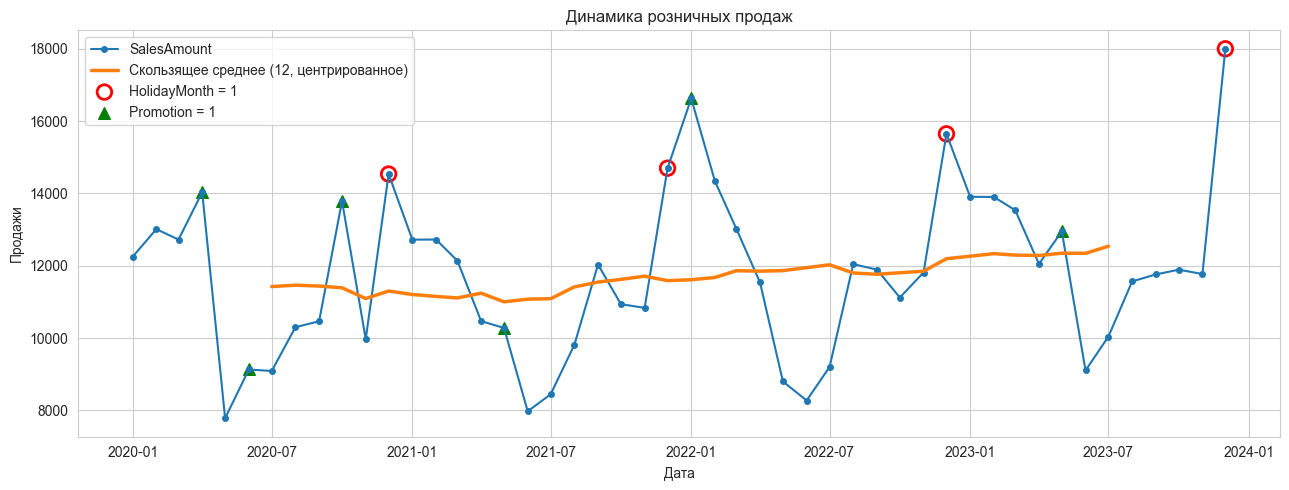

Праздничные месяцы: ['2020-12', '2021-12', '2022-12', '2023-12']
Месяцы с акциями  : ['2020-04', '2020-06', '2020-10', '2021-05', '2022-01', '2023-05']


In [60]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(y_full, marker="o", ms=4, label="SalesAmount")
ax.plot(y_full.rolling(12, center=True).mean(), lw=2.5, label="Скользящее среднее (12, центрированное)")
hol = y_full[df["HolidayMonth"] == 1]; pro = y_full[df["Promotion"] == 1]
ax.scatter(hol.index, hol.values, s=110, facecolors="none", edgecolors="red", lw=2, label="HolidayMonth = 1")
ax.scatter(pro.index, pro.values, marker="^", s=70, color="green", label="Promotion = 1")
ax.set_title("Динамика розничных продаж"); ax.set_xlabel("Дата"); ax.set_ylabel("Продажи"); ax.legend()
plt.tight_layout(); plt.show()

print("Праздничные месяцы:", list(df.index[df["HolidayMonth"] == 1].strftime("%Y-%m")))
print("Месяцы с акциями  :", list(df.index[df["Promotion"] == 1].strftime("%Y-%m")))

## 2.1.2 Скользящие статистики, распределение, годовая динамика

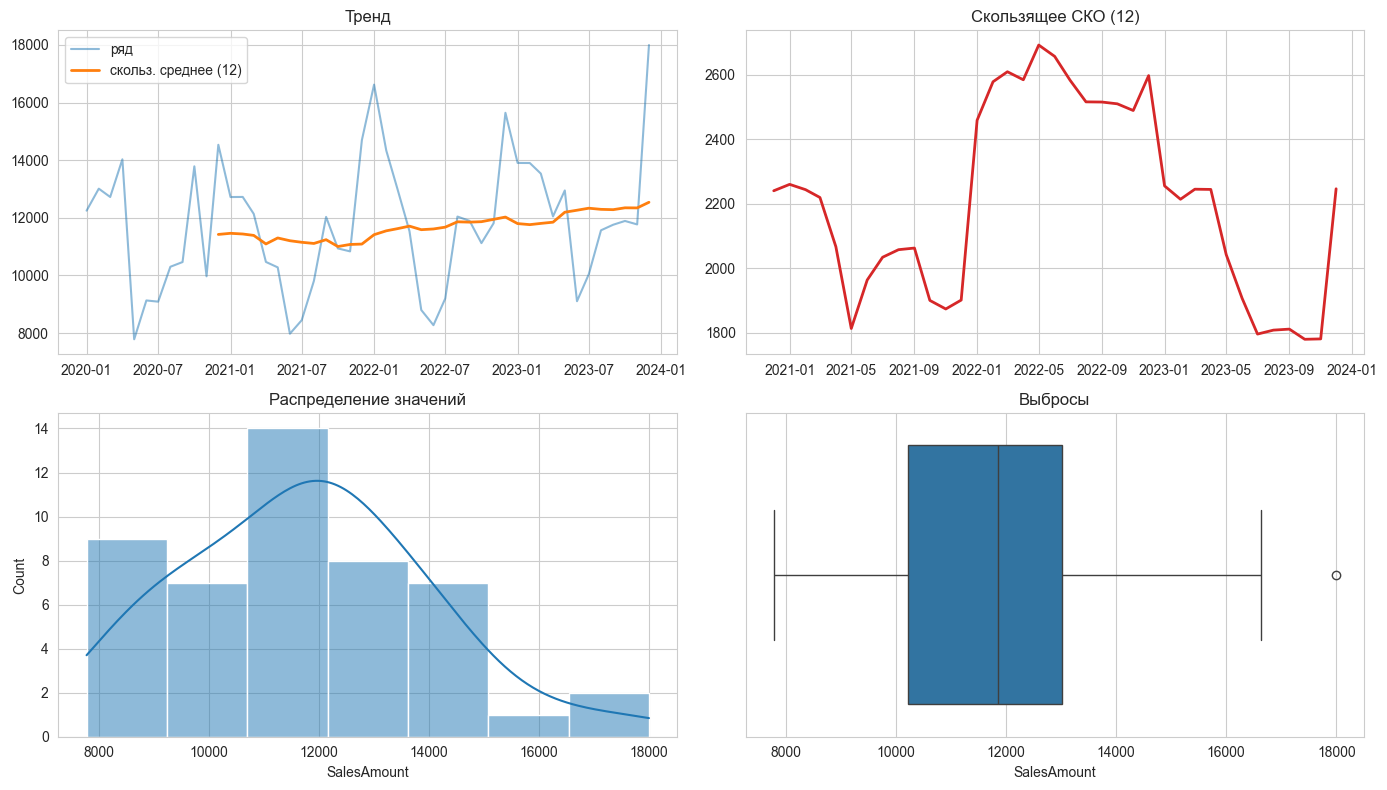

,mean,std,min,max,"YoY рост среднего, %"
Date,,,,,
2020,11422.2,2240.0,7783.0,14534.0,NaN
2021,11088.0,1901.5,7976.0,14696.0,-2.9
2022,12025.3,2596.6,8273.0,16623.0,8.5
2023,12538.6,2246.2,9104.0,17996.0,4.3


In [61]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(y_full, alpha=.5, label="ряд"); axes[0, 0].plot(y_full.rolling(12).mean(), lw=2, label="скольз. среднее (12)")
axes[0, 0].set_title("Тренд"); axes[0, 0].legend()
axes[0, 1].plot(y_full.rolling(12).std(), lw=2, color="C3")
axes[0, 1].set_title("Скользящее СКО (12)")

sns.histplot(y_full, kde=True, ax=axes[1, 0]); axes[1, 0].set_title("Распределение значений")
sns.boxplot(x=y_full, ax=axes[1, 1]); axes[1, 1].set_title("Выбросы")
plt.tight_layout(); plt.show()

yearly = y_full.groupby(y_full.index.year).agg(["mean", "std", "min", "max"])
yearly["YoY рост среднего, %"] = yearly["mean"].pct_change() * 100
display(yearly.round(1))

## 2.1.3 Сезонные профили

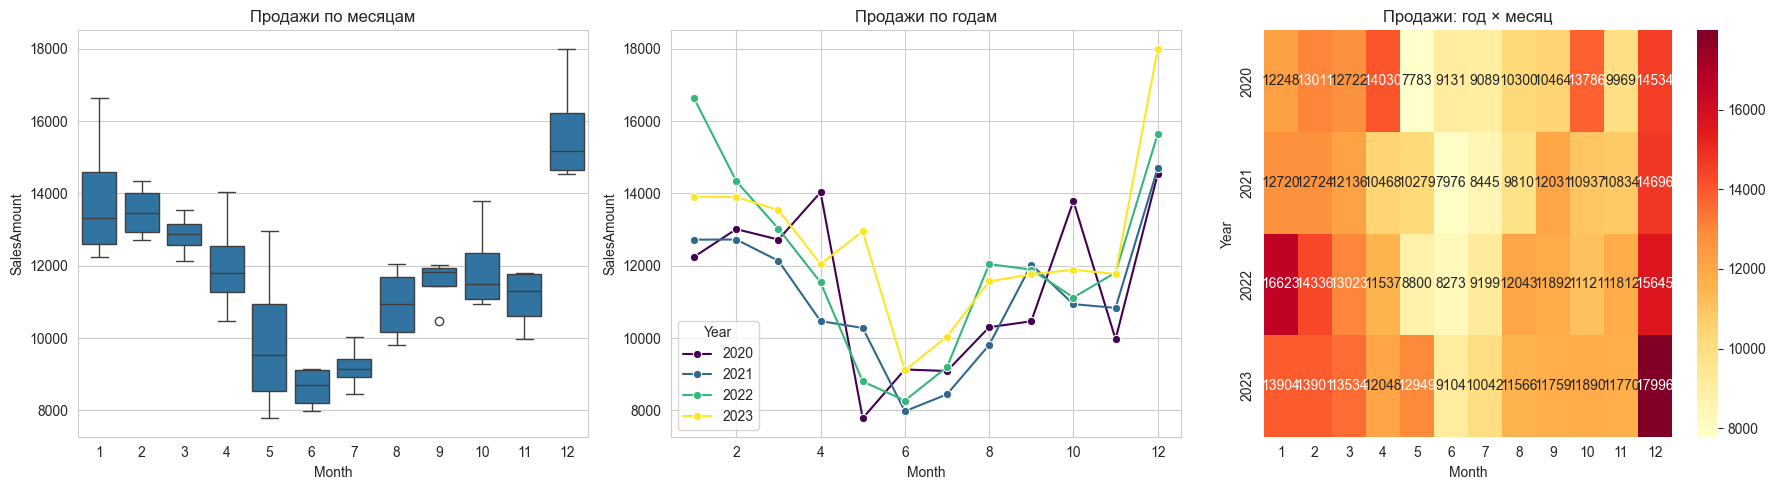

In [62]:
tmp = df.copy(); tmp["Month"] = tmp.index.month; tmp["Year"] = tmp.index.year
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=tmp, x="Month", y="SalesAmount", ax=axes[0]); axes[0].set_title("Продажи по месяцам")
sns.lineplot(data=tmp, x="Month", y="SalesAmount", hue="Year", marker="o", palette="viridis", ax=axes[1])
axes[1].set_title("Продажи по годам")
sns.heatmap(tmp.pivot(index="Year", columns="Month", values="SalesAmount"), annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[2])
axes[2].set_title("Продажи: год × месяц")
plt.tight_layout(); plt.show()

## 2.1.4 Автокорреляция временного ряда

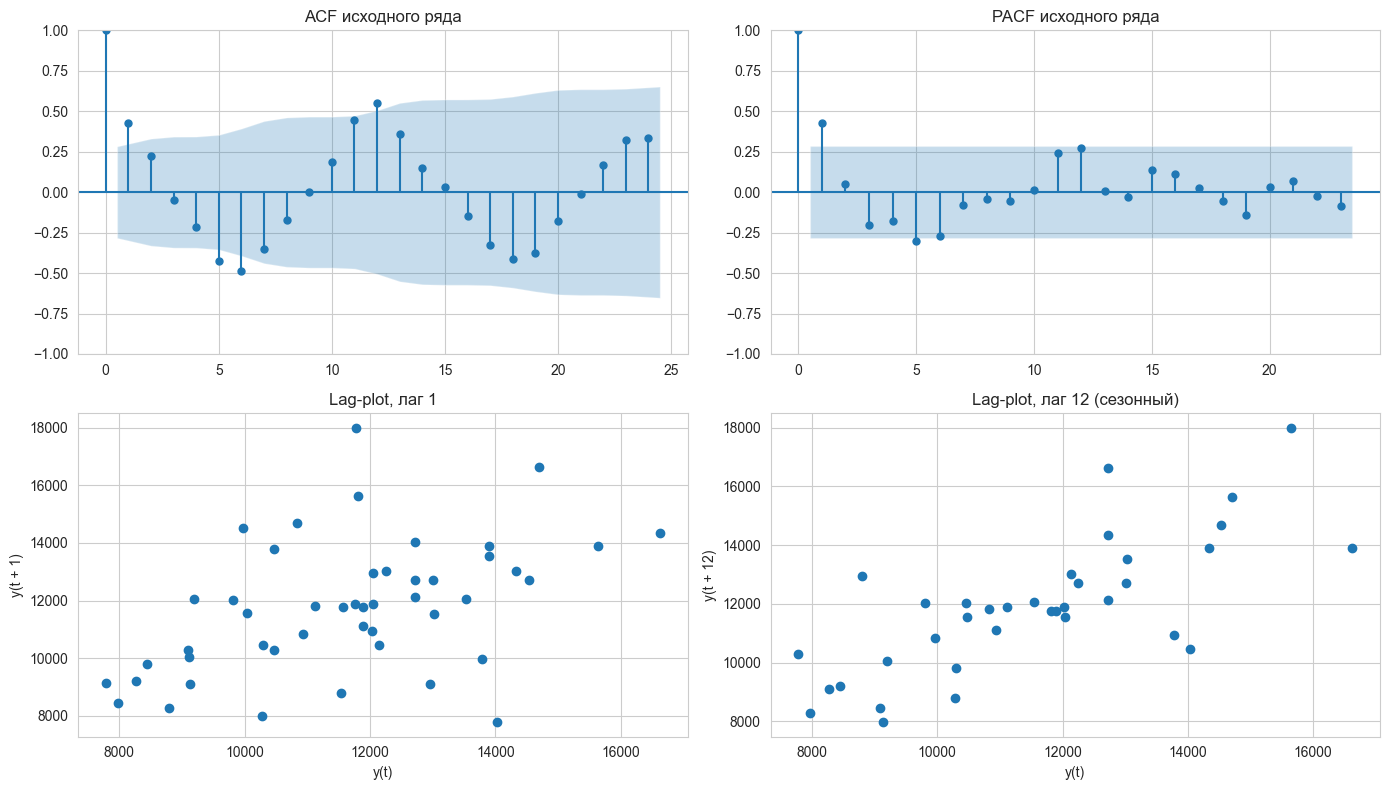

Автокорреляция, лаг 1: 0.47
Автокорреляция, лаг 12: 0.747


In [63]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(y_full, lags=24, ax=axes[0, 0]); axes[0, 0].set_title("ACF исходного ряда")
plot_pacf(y_full, lags=len(y_full)//2 - 1, method="ywm", ax=axes[0, 1]); axes[0, 1].set_title("PACF исходного ряда")
pd.plotting.lag_plot(y_full, lag=1, ax=axes[1, 0]); axes[1, 0].set_title("Lag-plot, лаг 1")
pd.plotting.lag_plot(y_full, lag=12, ax=axes[1, 1]); axes[1, 1].set_title("Lag-plot, лаг 12 (сезонный)")
plt.tight_layout(); plt.show()
print("Автокорреляция, лаг 1:", round(y_full.autocorr(1), 3))
print("Автокорреляция, лаг 12:", round(y_full.autocorr(12), 3))

## 2.1.5 Влияние `Promotion` и `HolidayMonth`

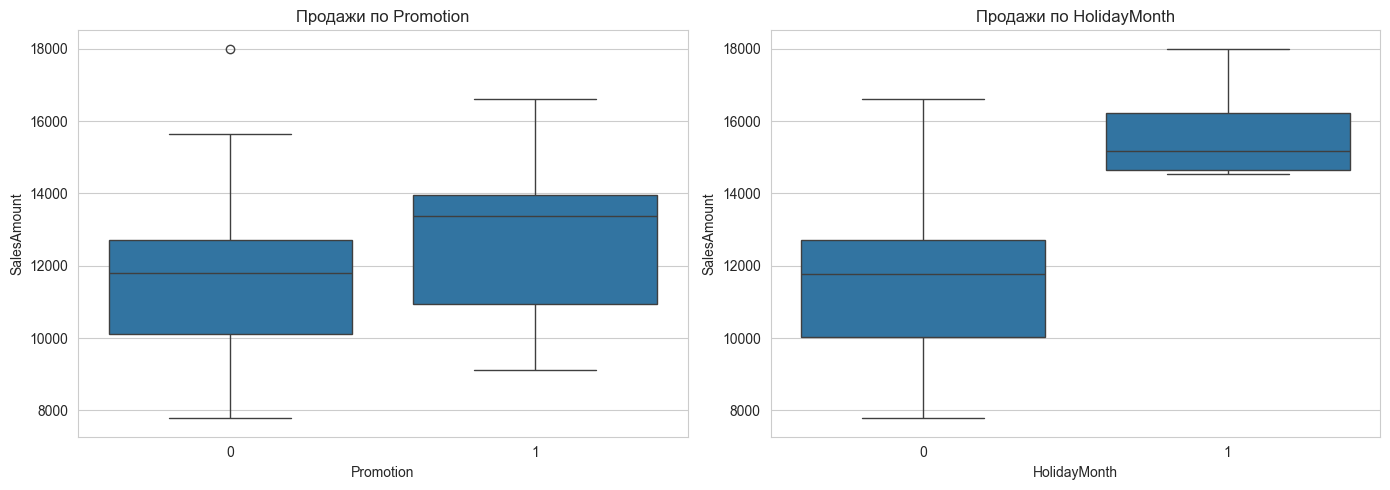

,n(=1),Среднее(=1),Среднее(=0),Разница,Манн-Уитни p
Фактор,,,,,
Promotion,6,12799.667,11621.238,1178.429,0.263
HolidayMonth,4,15717.750,11409.523,4308.227,0.000


,coef,p-value
const,10457.0139,0.0000
t,30.4420,0.1176
Promotion,1850.5063,0.1331
HolidayMonth,4377.9168,0.0000


In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Promotion", y="SalesAmount", ax=axes[0]); axes[0].set_title("Продажи по Promotion")
sns.boxplot(data=df, x="HolidayMonth", y="SalesAmount", ax=axes[1]); axes[1].set_title("Продажи по HolidayMonth")
plt.tight_layout(); plt.show()

rows = []
for col in ["Promotion", "HolidayMonth"]:
    a, b = y_full[df[col] == 1], y_full[df[col] == 0]
    mw = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"Фактор": col, "n(=1)": len(a), "Среднее(=1)": a.mean(), "Среднее(=0)": b.mean(),
                 "Разница": a.mean() - b.mean(), "Манн-Уитни p": mw.pvalue})
effects_df = pd.DataFrame(rows).set_index("Фактор"); display(effects_df.round(3))

X = sm.add_constant(pd.DataFrame({"t": np.arange(len(df)), "Promotion": df["Promotion"], "HolidayMonth": df["HolidayMonth"]}, index=df.index).astype(float))
ols = sm.OLS(y_full, X).fit(cov_type="HC3")
ols_tab = pd.DataFrame({"coef": ols.params, "p-value": ols.pvalues}); display(ols_tab.round(4))

## 2.1.6 Выбросы

СКО остатков STL: 883
Выбросов: 1


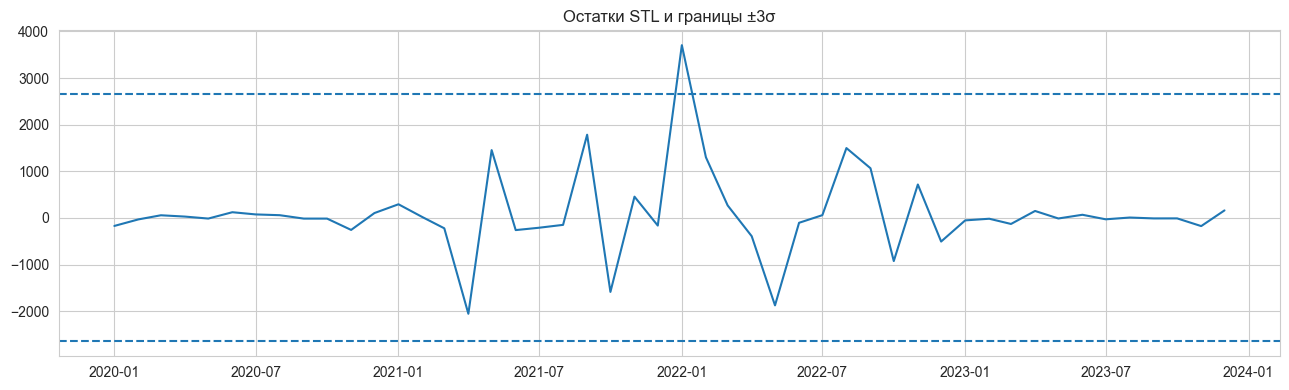

In [65]:
stl_full = STL(y_full, period=PERIOD, robust=True).fit()
r = stl_full.resid
sigma_r = r.std()
outliers = r[np.abs(r) > 3 * sigma_r]

print(f"СКО остатков STL: {sigma_r:.0f}")
print(f"Выбросов: {len(outliers)}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(r)
ax.axhline(3 * sigma_r, ls="--")
ax.axhline(-3 * sigma_r, ls="--")
ax.set_title("Остатки STL и границы ±3σ")
plt.tight_layout()
plt.show()

## 2.1.7 Стационарность и сезонность

- **ADF:** проверяет наличие единичного корня (нестационарность)
- **KPSS:** проверяет стационарность
- Ряд считаем стационарным, если ADF подтверждает стационарность, а KPSS не выявляет её нарушение
- Если результаты тестов различаются, это отмечается в выводах
- **Сила сезонности и тренда** оценивается по STL. Чем выше `F_s`, тем сильнее сезонность; чем выше `F_t`, тем сильнее тренд
- При `F_s > 0.64` сезонность считается достаточно сильной для сезонного дифференцирования

In [66]:
def adf_kpss(series):
    s = pd.Series(series).dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      
        adf_p = adfuller(s, autolag="AIC")[1]
        kpss_p = kpss(s, regression="c", nlags="auto")[1]
    return adf_p, kpss_p

def verdict(adf_p, kpss_p):
    a, k = adf_p < ALPHA, kpss_p > ALPHA
    return "стационарен" if (a and k) else "нестационарен" if (not a and not k) else "тесты противоречат"

def strengths(y, s=PERIOD):
    res = STL(y, period=s, robust=True).fit()
    Fs = max(0.0, 1 - np.var(res.resid) / np.var(res.seasonal + res.resid))
    Ft = max(0.0, 1 - np.var(res.resid) / np.var(res.trend + res.resid))
    return Fs, Ft

Fs_full, Ft_full = strengths(y_full)
print(f"Сила сезонности F_s = {Fs_full:.3f}   |   сила тренда F_t = {Ft_full:.3f}")

variants = {"Исходный ряд": y_full, "d=1": y_full.diff(), f"D=1 (лаг {PERIOD})": y_full.diff(PERIOD),
            "d=1 и D=1": y_full.diff().diff(PERIOD)}
rows = []
for name, s_ in variants.items():
    ap, kp = adf_kpss(s_)
    rows.append({"Ряд": name, "ADF p": ap, "KPSS p (усечено)": kp, "Вердикт": verdict(ap, kp)})
stationarity_df = pd.DataFrame(rows); display(stationarity_df.round(4))

Сила сезонности F_s = 0.839   |   сила тренда F_t = 0.257


,Ряд,ADF p,KPSS p (усечено),Вердикт
0,Исходный ряд,0.0002,0.1,стационарен
1,d=1,0.0000,0.1,стационарен
2,D=1 (лаг 12),0.0053,0.1,стационарен
3,d=1 и D=1,0.0001,0.1,стационарен


### Вывод по 2.1.1-2.1.7

In [67]:
slope_per_year = np.polyfit(np.arange(len(y_full)), stl_full.trend.values, 1)[0] * 12
hol_coef, hol_p = ols.params["HolidayMonth"], ols.pvalues["HolidayMonth"]
pro_coef, pro_p = ols.params["Promotion"], ols.pvalues["Promotion"]
raw_verdict = stationarity_df.loc[0, "Вердикт"]

print(f"1. Данные: {len(y_full)} месячных наблюдений")
print(f"2. Тренд: сила тренда F_t = {Ft_full:.2f}; оценка наклона тренда STL ≈ {slope_per_year:+.0f} ед./год "
      f"({'выраженный' if Ft_full > .64 else 'слабый/умеренный'} тренд)")
print(f"3. Сезонность: сила сезонности F_s = {Fs_full:.2f} → {'сезонность сильная, годовой период (12) подтверждается графиками годовых профилей' if Fs_full > FS_THRESH else 'сезонность умеренная/слабая'}")
print(f"Автокорреляция на лаге 12 = {y_full.autocorr(12):.2f} (на лаге 1 = {y_full.autocorr(1):.2f})")
print(f"4. Эффекты: HolidayMonth {hol_coef:+.0f} ед. (p={hol_p:.3f}, {'значим' if hol_p < ALPHA else 'не значим'}); "
      f"Promotion {pro_coef:+.0f} ед. (p={pro_p:.3f}, {'значим' if pro_p < ALPHA else 'не значим'}) при контроле тренда")
print(f"Праздничных месяцев всего {int(df['HolidayMonth'].sum())}, акций {int(df['Promotion'].sum())} - оценки эффектов опираются на малое число точек")
print(f"5. Выбросы по STL (3σ): {len(outliers)} шт." + (f" ({', '.join(outliers.index.strftime('%Y-%m'))})" if len(outliers) else ""))
print(f"6. Стационарность исходного ряда: {raw_verdict} (ADF p={stationarity_df.loc[0,'ADF p']:.4f}, KPSS p(усечено)={stationarity_df.loc[0,'KPSS p (усечено)']:.2f})"
      "Конкретные порядки d и D выбираются в 2.2 по тренировочной выборке, чтобы не использовать информацию из теста")

1. Данные: 48 месячных наблюдений
2. Тренд: сила тренда F_t = 0.26; оценка наклона тренда STL ≈ +380 ед./год (слабый/умеренный тренд)
3. Сезонность: сила сезонности F_s = 0.84 → сезонность сильная, годовой период (12) подтверждается графиками годовых профилей
Автокорреляция на лаге 12 = 0.75 (на лаге 1 = 0.47)
4. Эффекты: HolidayMonth +4378 ед. (p=0.000, значим); Promotion +1851 ед. (p=0.133, не значим) при контроле тренда
Праздничных месяцев всего 4, акций 6 - оценки эффектов опираются на малое число точек
5. Выбросы по STL (3σ): 1 шт. (2022-01)
6. Стационарность исходного ряда: стационарен (ADF p=0.0002, KPSS p(усечено)=0.10)Конкретные порядки d и D выбираются в 2.2 по тренировочной выборке, чтобы не использовать информацию из теста


## 2.1.8 Декомпозиция №1: классическая и STL

- **Классическая модель:** выделяет тренд и сезонность по скользящему среднему и средним значениям по месяцам
- **STL:** выделяет тренд и сезонность с помощью LOESS; `robust=True` уменьшает влияние выбросов
- Для выбора между аддитивной и мультипликативной моделью сравниваем качество остатков и их автокорреляцию

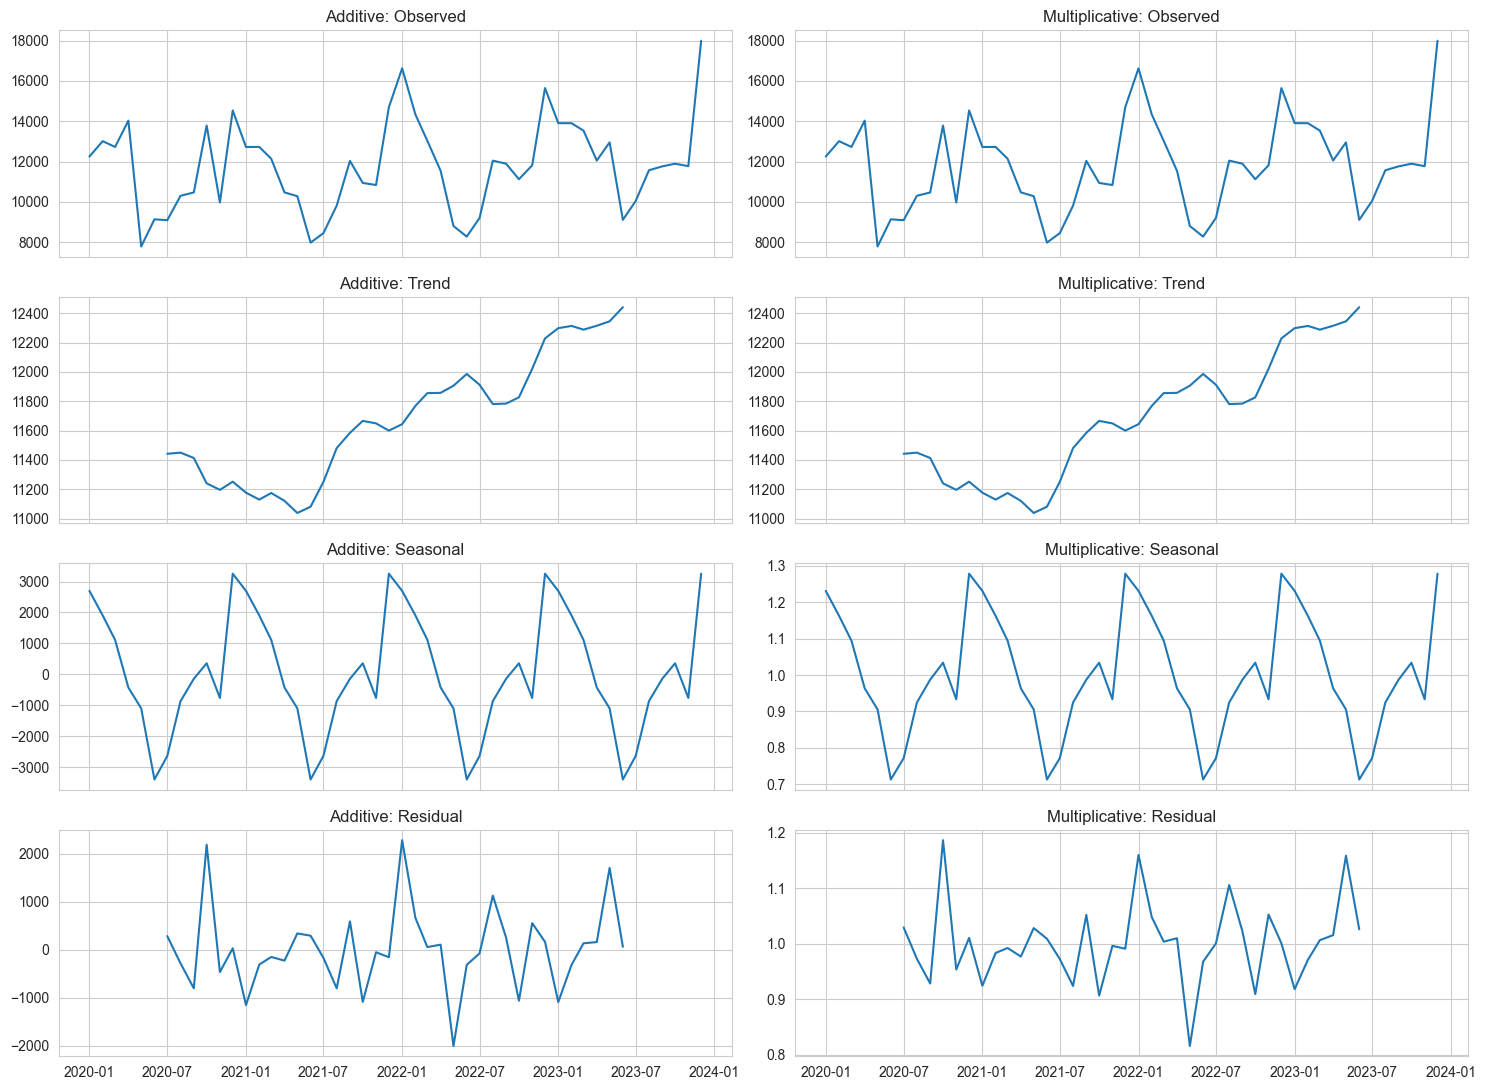

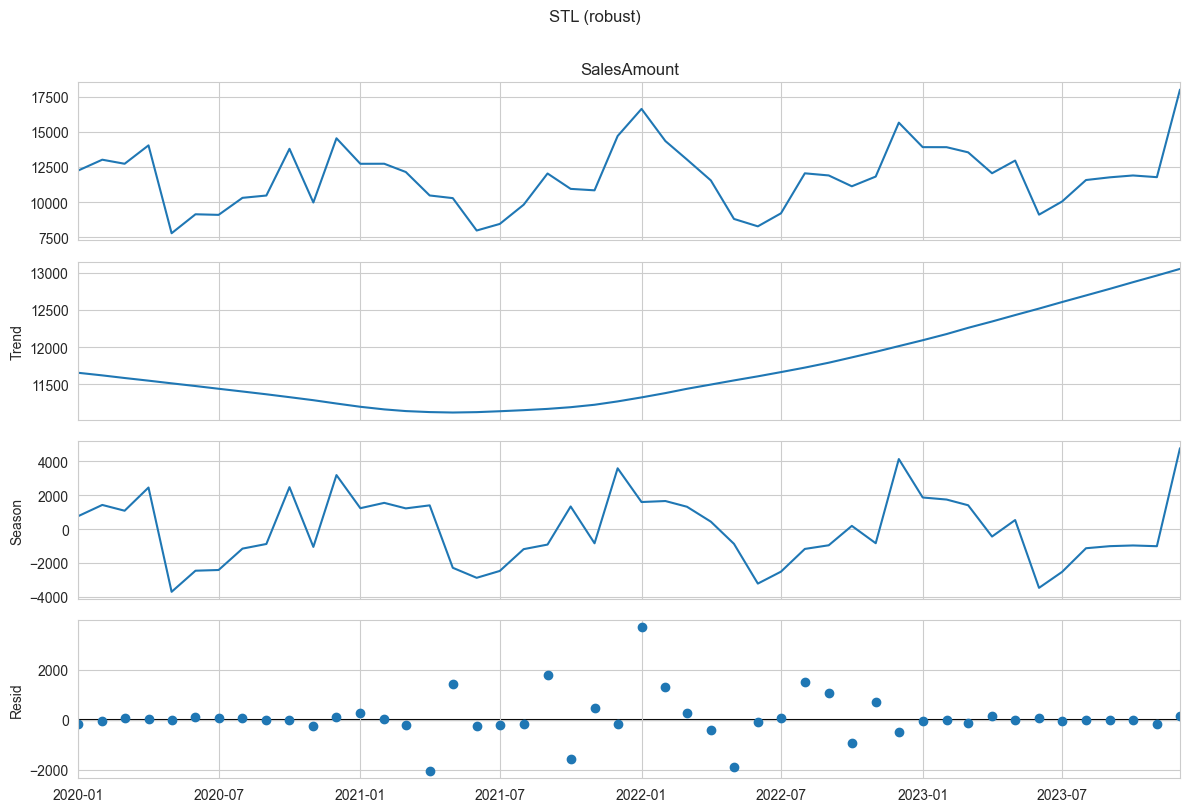

,Относительная ошибка остатка,Ljung-Box p (лаг 6),Точек остатка
Classical additive,0.0740,0.5532,36
Classical multiplicative,0.0733,0.6398,36
STL (robust),0.0750,0.2460,48


Spearman: -0.12 (p=0.404) - амплитуда существенно не меняется, подходит additive
Относительная ошибка остатка: add=0.0740, mul=0.0733. Итог по правилу: additive


In [68]:
dec_add = seasonal_decompose(y_full, model="additive", period=PERIOD)
dec_mul = seasonal_decompose(y_full, model="multiplicative", period=PERIOD)

fig, axes = plt.subplots(4, 2, figsize=(15, 11), sharex=True)
for i, (name, dec) in enumerate([("Additive", dec_add), ("Multiplicative", dec_mul)]):
    for j, (comp, title) in enumerate([(dec.observed, "Observed"), (dec.trend, "Trend"), (dec.seasonal, "Seasonal"), (dec.resid, "Residual")]):
        axes[j, i].plot(comp); axes[j, i].set_title(f"{name}: {title}")
plt.tight_layout(); plt.show()

fig = stl_full.plot(); fig.set_size_inches(12, 8); fig.suptitle("STL (robust)", y=1.01); plt.tight_layout(); plt.show()

# --- сравнение additive и multiplicative ---
res_add = dec_add.resid.dropna(); res_mul = dec_mul.resid.dropna()
cv_add = res_add.std() / y_full.mean()
cv_mul = res_mul.std()         
lb_add = acorr_ljungbox(res_add, lags=[6], return_df=True)["lb_pvalue"].iloc[0]
lb_mul = acorr_ljungbox(res_mul, lags=[6], return_df=True)["lb_pvalue"].iloc[0]
cv_stl = stl_full.resid.std() / y_full.mean()
decomp_cmp = pd.DataFrame({
    "Относительная ошибка остатка": [cv_add, cv_mul, cv_stl],
    "Ljung-Box p (лаг 6)": [lb_add, lb_mul, acorr_ljungbox(stl_full.resid, lags=[6], return_df=True)['lb_pvalue'].iloc[0]],
    "Точек остатка": [len(res_add), len(res_mul), len(stl_full.resid)]},
    index=["Classical additive", "Classical multiplicative", "STL (robust)"])
display(decomp_cmp.round(4))

amp_corr = stats.spearmanr(stl_full.trend, np.abs(stl_full.seasonal))
print(f"Spearman: {amp_corr.correlation:.2f} (p={amp_corr.pvalue:.3f}) - "
      f"{'амплитуда растёт с уровнем, подходит multiplicative' if amp_corr.pvalue < ALPHA and amp_corr.correlation > 0 else 'амплитуда существенно не меняется, подходит additive'}")
# multiplicative выбираем только при заметном преимуществе
# иначе выбираем более простую additive
mult_better = (cv_mul < 0.95 * cv_add) or (amp_corr.pvalue < ALPHA and amp_corr.correlation > 0)
best_classic = "multiplicative" if mult_better else "additive"
print(f"Относительная ошибка остатка: add={cv_add:.4f}, mul={cv_mul:.4f}. Итог по правилу: {best_classic}")

### Вывод по классической декомпозиции и STL

In [69]:
seas_amp = stl_full.seasonal.max() - stl_full.seasonal.min()
peak_month = stl_full.seasonal.groupby(stl_full.seasonal.index.month).mean().idxmax()
low_month = stl_full.seasonal.groupby(stl_full.seasonal.index.month).mean().idxmin()

print(f"• Размах сезонности: {seas_amp:.0f}; максимум - месяц {peak_month}, минимум - месяц {low_month}.")
print(f"• Лучшая классическая модель: {best_classic}; STL: {cv_stl:.3f}.")
print("• STL использует весь ряд, классические методы теряют данные по краям.")
print(f"• Ljung-Box: add p={lb_add:.3f}, mul p={lb_mul:.3f}.")
print("• Период 12 задан заранее; FFT и вейвлеты помогают его проверить.")

• Размах сезонности: 8497; максимум - месяц 12, минимум - месяц 6.
• Лучшая классическая модель: additive; STL: 0.075.
• STL использует весь ряд, классические методы теряют данные по краям.
• Ljung-Box: add p=0.553, mul p=0.640.
• Период 12 задан заранее; FFT и вейвлеты помогают его проверить.


## 2.1.9 Декомпозиция №2: спектральный анализ (FFT)

Перед FFT удаляется линейный тренд. Амплитуда считается как `A_k = 2·|X_k|/N`. Для каждого пика оценивается доля дисперсии `A²/2 / Var(x)`.

Значимость главного пика проверяется **g-тестом Фишера** (H₀ - белый шум: ни одна частота не доминирует).

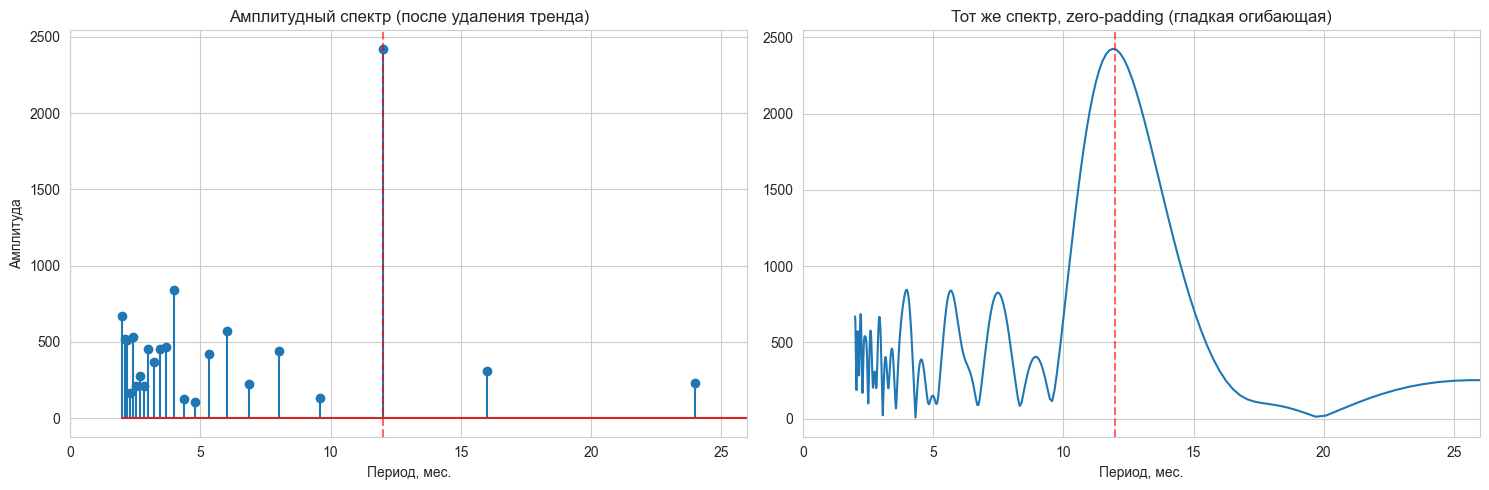

,"Период, мес.",Амплитуда,Доля дисперсии
0,12.000,2421.303,0.612
1,4.000,840.412,0.074
2,2.000,669.441,0.047
3,6.000,573.037,0.034
4,2.400,535.225,0.030
5,2.087,517.330,0.028


Главный пик: период 12.00 мес.; g-тест Фишера p = 9.1e-09
Топ-3 периода: [12.0, 4.0, 2.0] | среди них 12 мес.: True | все - гармоники 12: True


In [70]:
x = y_full.values.astype(float); N = len(x)
xd = detrend(x, type="linear")

X = sfft.rfft(xd); f = sfft.rfftfreq(N, d=1.0)
amp = 2 * np.abs(X) / N
mask = f > 0
per, A = 1 / f[mask], amp[mask]
var_share = (A ** 2 / 2) / np.var(xd)

# g-тест Фишера для главного пика
P = (np.abs(X[1:]) ** 2); P = P[:-1] if N % 2 == 0 else P
g = P.max() / P.sum(); m = len(P)
p_fisher = min(1.0, sum((-1) ** (j - 1) * comb(m, j) * (1 - j * g) ** (m - 1) for j in range(1, int(1 / g) + 1)))

# дополнение нулями только для более плавного графика
Xp = sfft.rfft(xd, n=1024); fp = sfft.rfftfreq(1024, d=1.0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].stem(per, A); axes[0].set_xlabel("Период, мес."); axes[0].set_ylabel("Амплитуда")
axes[0].set_title("Амплитудный спектр (после удаления тренда)"); axes[0].set_xlim(0, 26)
axes[1].plot(1 / fp[1:], 2 * np.abs(Xp[1:]) / N); axes[1].set_xlim(0, 26)
axes[1].set_xlabel("Период, мес."); axes[1].set_title("Тот же спектр, zero-padding (гладкая огибающая)")
for a_ in axes: a_.axvline(12, ls="--", c="r", alpha=.6)
plt.tight_layout(); plt.show()

fft_table = (pd.DataFrame({"Период, мес.": per, "Амплитуда": A, "Доля дисперсии": var_share})
             .sort_values("Амплитуда", ascending=False).head(6).reset_index(drop=True))
display(fft_table.round(3))
fft_main_period = fft_table.loc[0, "Период, мес."]
def is_harmonic(p, base=12, tol=0.3):
    # период p является основным (12) или его гармоникой 12/k
    return any(abs(p - base / k) < tol for k in range(1, 7))
top3 = fft_table.head(3)["Период, мес."].tolist()
fft_has_12 = any(abs(p - 12) < 0.5 for p in top3)
fft_all_harm = all(is_harmonic(p) for p in top3)
print(f"Главный пик: период {fft_main_period:.2f} мес.; g-тест Фишера p = {p_fisher:.2g}")
print(f"Топ-3 периода: {[round(p, 2) for p in top3]} | среди них 12 мес.: {fft_has_12} | все - гармоники 12: {fft_all_harm}")

### Вывод по FFT

In [71]:
harm = [12, 6, 4, 3, 2.4]
found = [h for h in harm if np.any(np.isclose(per, h, atol=0.05) & (var_share > 0.02))]
print(f"- Доминирующий период: {fft_main_period:.1f} мес. (доля дисперсии {fft_table.loc[0,'Доля дисперсии']:.0%}); "
      f"g-тест Фишера: p={p_fisher:.2g} -> {'пик статистически значим' if p_fisher < ALPHA else 'пик НЕ значим на уровне 5%'}")
if not fft_has_12 and fft_all_harm:
    print(f"Главный пик ({fft_main_period:.1f} мес.) - гармоника годового цикла (12/k): спектр согласуется с годовой периодичностью несинусоидальной формы")
print(f"- Периоды из набора гармоник годовой сезонности (12, 6, 4, 3, 2.4) с долей дисперсии > 2%: {found}")

- Доминирующий период: 12.0 мес. (доля дисперсии 61%); g-тест Фишера: p=9.1e-09 -> пик статистически значим
- Периоды из набора гармоник годовой сезонности (12, 6, 4, 3, 2.4) с долей дисперсии > 2%: [12, 6, 4, 3, 2.4]


## 2.1.10 Декомпозиция №3: вейвлет-анализ

### CWT с вейвлетом Морле

- Перед анализом убран тренд и ряд стандартизован.
- Рассматриваются периоды от 2 до 24 месяцев.
- Мощность нормирована по масштабу.
- Учтён конус влияния (COI), чтобы не учитывать краевые эффекты.

Для выбранного вейвлета масштаб соответствует периоду в месяцах.

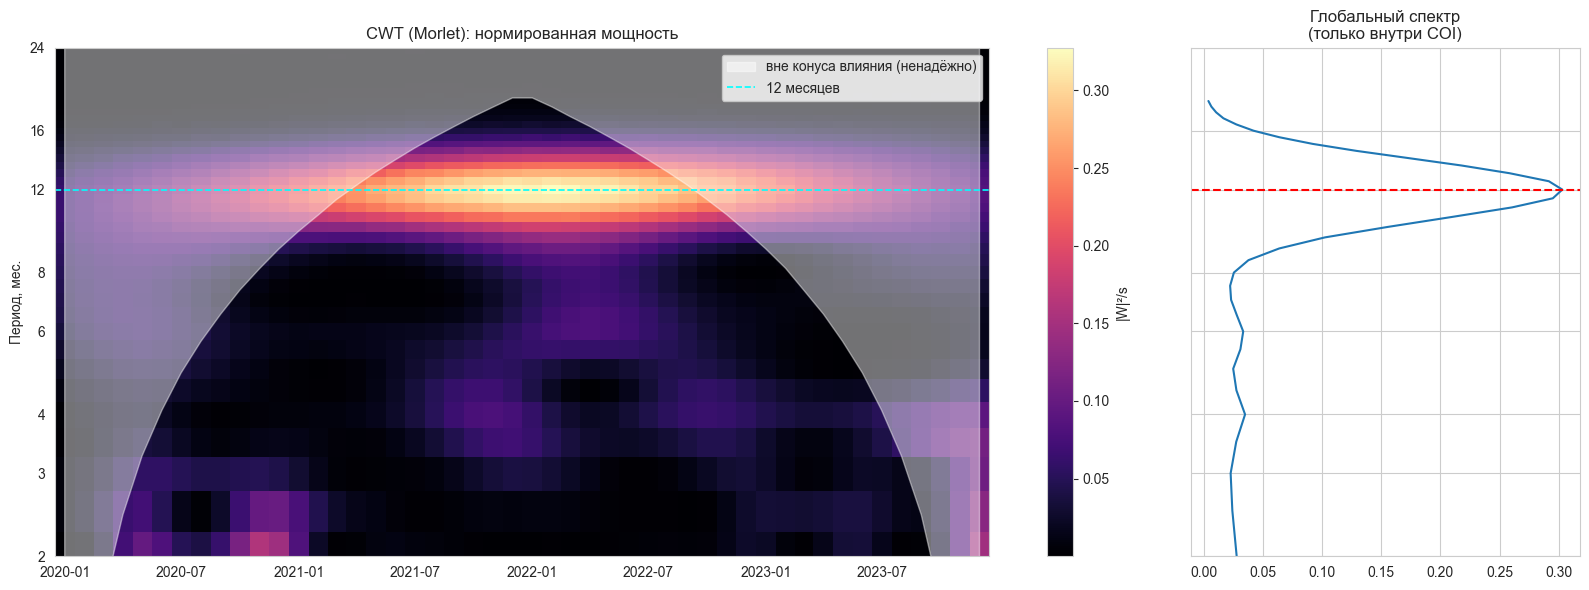

,мощность
"период, мес.",
12.0,0.303
11.5,0.295
12.5,0.292
11.0,0.261
13.0,0.258
13.5,0.218


Локальные максимумы глобального спектра: {12.0: 0.303, 4.0: 0.035, 6.0: 0.033}
Максимум глобального вейвлет-спектра: период ≈ 12.0 мес. (в спектр включены периоды ≤ 16.0 мес., для которых есть ≥8 надёжных точек)


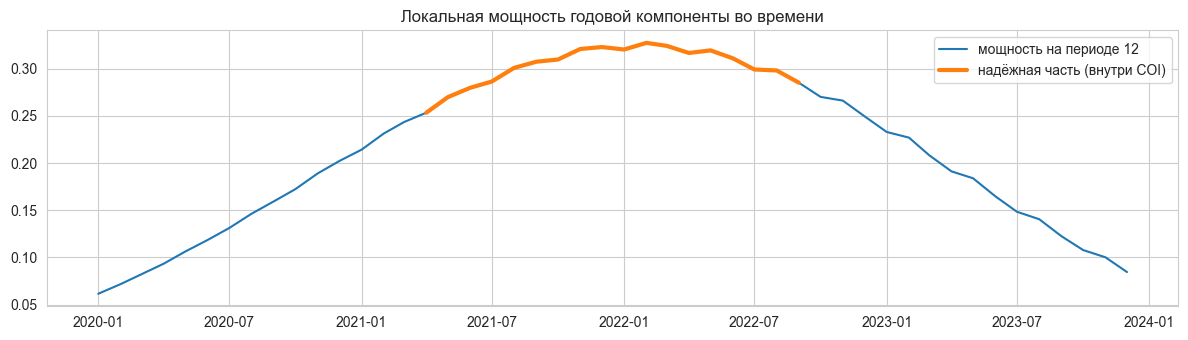

In [72]:
z = detrend(y_full.values.astype(float)); z = (z - z.mean()) / z.std()
wname, B = "cmor1.5-1.0", 1.5

periods_grid = np.arange(2, 24.01, 0.5)
scales = pywt.central_frequency(wname) * periods_grid  # масштаб = C·период (при шаге 1 месяц)
coef, freqs_cwt = pywt.cwt(z, scales, wname, sampling_period=1.0)
periods_cwt = 1.0 / freqs_cwt
power = (np.abs(coef) ** 2) / scales[:, None]  # нормировка на масштаб

# область внутри конуса влияния
t_idx = np.arange(len(z))
edge_dist = np.minimum(t_idx, len(z) - 1 - t_idx)
valid = (np.sqrt(B) * scales[:, None]) <= edge_dist[None, :]
power_valid = np.where(valid, power, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 1]}, sharey=True)
mesh = axes[0].pcolormesh(y_full.index, periods_cwt, power, shading="auto", cmap="magma")
coi_period = np.minimum(edge_dist / np.sqrt(B), periods_grid.max())
axes[0].fill_between(y_full.index, coi_period, periods_grid.max(), color="white", alpha=.45, label="вне конуса влияния (ненадёжно)")
axes[0].axhline(12, ls="--", c="cyan", lw=1.2, label="12 месяцев")
axes[0].set_yscale("log", base=2); axes[0].set_ylim(2, 24)
axes[0].set_yticks([2, 3, 4, 6, 8, 12, 16, 24]); axes[0].get_yaxis().set_major_formatter(plt.ScalarFormatter())
axes[0].set_ylabel("Период, мес."); axes[0].set_title("CWT (Morlet): нормированная мощность"); axes[0].legend(loc="upper right")
plt.colorbar(mesh, ax=axes[0], label="|W|²/s")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")                    
    gws = np.nanmean(power_valid, axis=1)  # глобальный вейвлет-спектр только по надёжным точкам
n_valid = valid.sum(axis=1)
axes[1].plot(gws, periods_cwt); axes[1].axhline(12, ls="--", c="r"); axes[1].set_title("Глобальный спектр\n(только внутри COI)")
plt.tight_layout(); plt.show()

gws_s = pd.Series(gws, index=periods_cwt).dropna()
gws_s = gws_s[[n_valid[i] >= 8 for i in range(len(gws)) if not np.isnan(gws[i])]]   # минимум 8 надёжных точек
cwt_main_period = gws_s.idxmax()
cwt_table = gws_s.sort_values(ascending=False).head(6).rename("мощность").to_frame().rename_axis("период, мес.")
display(cwt_table.round(3))
pk_idx, _ = find_peaks(gws_s.values)
cwt_peaks = gws_s.iloc[pk_idx].sort_values(ascending=False)
cwt_peak_near_12 = any((abs(p - 12) <= 1.5) and (v >= 0.5 * gws_s.max()) for p, v in cwt_peaks.items())
print("Локальные максимумы глобального спектра:", {round(p, 1): round(v, 3) for p, v in cwt_peaks.head(4).items()})
print(f"Максимум глобального вейвлет-спектра: период ≈ {cwt_main_period:.1f} мес. "
      f"(в спектр включены периоды ≤ {gws_s.index.max():.1f} мес., для которых есть ≥8 надёжных точек)")

# проверяем, сохраняется ли период около 12 месяцев
i12 = np.argmin(np.abs(periods_cwt - 12))
p12 = pd.Series(power[i12], index=y_full.index)
fig, ax = plt.subplots(figsize=(12, 3.5)); ax.plot(p12, label="мощность на периоде 12"); 
ax.plot(p12.where(valid[i12]), lw=3, label="надёжная часть (внутри COI)"); ax.legend(); ax.set_title("Локальная мощность годовой компоненты во времени")
plt.tight_layout(); plt.show()

### DWT с вейвлетом Добеши

Для N = 48 вейвлет `db4` (фильтр длины 8) допускает **не более 2 уровней** (`pywt.dwt_max_level`), и годовой цикл (8-16 мес.) оказался бы смешан с остатком-аппроксимацией. Поэтому используется `db2` (Daubechies-2, фильтр длины 4), допускающий 4 уровня: детали уровня *j* отвечают периодам ≈ 2ʲ…2ʲ⁺¹ мес. Режим `periodization` сохраняет длину ряда; каждая компонента восстанавливается обратным преобразованием при обнулении остальных уровней.

Вейвлет db2: максимальный уровень для N=48 равен 4, используем 4


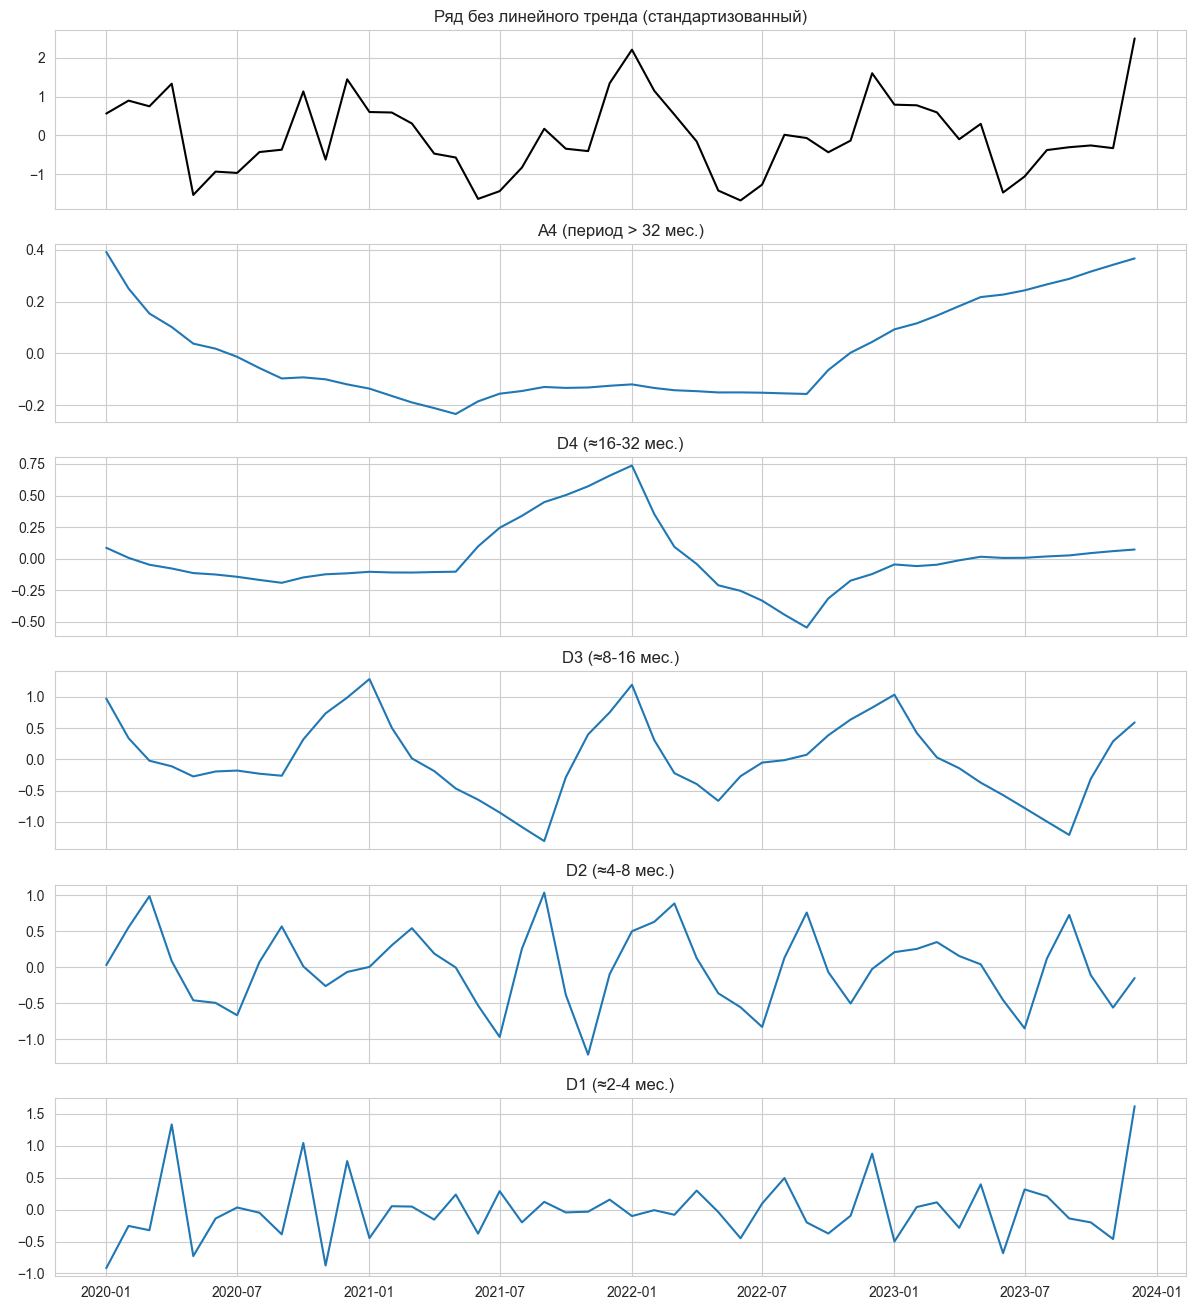

,Доля дисперсии ряда
Компонента,
A4 (период > 32 мес.),0.033
D4 (≈16-32 мес.),0.067
D3 (≈8-16 мес.),0.390
D2 (≈4-8 мес.),0.260
D1 (≈2-4 мес.),0.251


Детализирующий уровень с наибольшей долей дисперсии: D3 (≈8-16 мес.)


In [73]:
dwt_wavelet = "db2"
max_lvl = pywt.dwt_max_level(len(z), dwt_wavelet); level = min(4, max_lvl)
print(f"Вейвлет {dwt_wavelet}: максимальный уровень для N={len(z)} равен {max_lvl}, используем {level}")
coeffs = pywt.wavedec(z, dwt_wavelet, level=level, mode="periodization")

comps, names = [], []
for k in range(len(coeffs)):
    keep = [np.zeros_like(c) for c in coeffs]; keep[k] = coeffs[k]
    comps.append(pywt.waverec(keep, dwt_wavelet, mode="periodization")[:len(z)])
    names.append(f"A{level} (период > {2**(level+1)} мес.)" if k == 0 else f"D{level - k + 1} (≈{2**(level-k+1)}-{2**(level-k+2)} мес.)")

fig, axes = plt.subplots(len(comps) + 1, 1, figsize=(12, 2.2 * (len(comps) + 1)), sharex=True)
axes[0].plot(y_full.index, z, c="k"); axes[0].set_title("Ряд без линейного тренда (стандартизованный)")
for ax_, c_, n_ in zip(axes[1:], comps, names):
    ax_.plot(y_full.index, c_); ax_.set_title(n_)
plt.tight_layout(); plt.show()

dwt_tab = pd.DataFrame({"Компонента": names, "Доля дисперсии ряда": [np.var(c_) / np.var(z) for c_ in comps]}).set_index("Компонента")
dwt_tab["Доля дисперсии ряда"] = dwt_tab["Доля дисперсии ряда"]
display(dwt_tab.round(3))
details_only = dwt_tab.iloc[1:]
dwt_main = details_only["Доля дисперсии ряда"].idxmax()
print("Детализирующий уровень с наибольшей долей дисперсии:", dwt_main)

### Вывод по вейвлет-анализу

In [74]:
cwt_ok = (abs(cwt_main_period - 12) <= 2) or is_harmonic(cwt_main_period, tol=0.5) or cwt_peak_near_12

print(f"• CWT: основной период ≈ {cwt_main_period:.1f} мес.; "
      f"максимум около 12 мес.: {'есть' if cwt_peak_near_12 else 'нет'}.")

print(f"• DWT ({dwt_wavelet}): наибольшая доля дисперсии у уровня «{dwt_main}»; "
      f"годовой цикл соответствует уровню D3.")

print("• Ограничения: при N=48 нельзя надёжно анализировать периоды больше 24 мес.; "
      "результат зависит от выбранного вейвлета и краевых эффектов.")

• CWT: основной период ≈ 12.0 мес.; максимум около 12 мес.: есть.
• DWT (db2): наибольшая доля дисперсии у уровня «D3 (≈8-16 мес.)»; годовой цикл соответствует уровню D3.
• Ограничения: при N=48 нельзя надёжно анализировать периоды больше 24 мес.; результат зависит от выбранного вейвлета и краевых эффектов.


## 2.1.11 Сравнение методов декомпозиции

In [75]:
summary = pd.DataFrame([
    {"Метод": "Classical", "Результат": best_classic, "Период": "12 мес.", "Во времени": "нет"},
    {"Метод": "STL", "Результат": f"Fs={Fs_full:.2f}, Ft={Ft_full:.2f}", "Период": "12 мес.", "Во времени": "да"},
    {"Метод": "FFT", "Результат": f"{fft_main_period:.1f} мес.", "Период": "найден", "Во времени": "нет"},
    {"Метод": "CWT", "Результат": f"{cwt_main_period:.1f} мес.", "Период": "найден", "Во времени": "да"},
    {"Метод": "DWT", "Результат": dwt_main, "Период": "D3", "Во времени": "да"},
]).set_index("Метод")

display(summary)

,Результат,Период,Во времени
Метод,,,
Classical,additive,12 мес.,нет
STL,"Fs=0.84, Ft=0.26",12 мес.,да
FFT,12.0 мес.,найден,нет
CWT,12.0 мес.,найден,да
DWT,D3 (≈8-16 мес.),D3,да


| Метод | Преимущества | Ограничения | Применимость к этому ряду |
|---|---|---|---|
| Classical add/mul | Простота, интерпретируемость | Фиксированный сезонный профиль; теряются точки на краях (при периоде 12 - по 6 с каждой стороны); период задаётся заранее | Подходит для первичной оценки, но на 48 точках теряет 25% остатка |
| STL | Устойчив к выбросам, гибкий тренд и сезонность, нет потери краёв | Только аддитивная форма; период задаётся заранее; параметры сглаживания влияют на результат | Основной инструмент для количественной оценки F_s, F_t и поиска выбросов |
| FFT | Объективно *обнаруживает* периоды; есть статистический тест значимости пика | Глобальный; не локализует во времени; чувствителен к тренду; разрешение 1/N | Хорошо подходит для подтверждения периода 12 и выявления гармоник |
| CWT | Показывает, как периодичность меняется во времени | Краевые эффекты, сложная интерпретация, зависит от выбранного вейвлета; на N=48 надёжен только до периодов ≈ 12-16 мес. | Информативен для проверки устойчивости годового цикла, но не для периодов > 16 мес. |
| DWT | Компактное многоуровневое разложение, возможность реконструкции | Дискретные уровни (степени 2) - период 12 «размазан» между D2 и D3; зависит от вейвлета/уровня | Вспомогательный метод, удобен для шумоподавления |

### Общий вывод по 2.1

In [76]:
agree = {
    "STL": Fs_full > FS_THRESH,
    "FFT": (fft_has_12 or fft_all_harm) and p_fisher < ALPHA,
    "CWT": cwt_ok,
}

print("Проверка годовой сезонности (12 мес.):")
for k, v in agree.items():
    print(f"{k}: {'подтверждает' if v else 'не подтверждает'}")

n_yes = sum(agree.values())
print(f"\n- Сезонность подтверждают {n_yes} из {len(agree)} методов.")

print(f"- Для модели используем период s=12.")
print(f"- Выбранная форма декомпозиции: {best_classic}.")
print(f"- HolidayMonth учитывается в SARIMAX как дополнительная переменная.")

Проверка годовой сезонности (12 мес.):
STL: подтверждает
FFT: подтверждает
CWT: подтверждает

- Сезонность подтверждают 3 из 3 методов.
- Для модели используем период s=12.
- Выбранная форма декомпозиции: additive.
- HolidayMonth учитывается в SARIMAX как дополнительная переменная.


# 2.2 Построение прогнозных моделей

## 2.2.1 Разбиение выборки

Первые 36 месяцев - обучение, последние 12 - тест (содержит полный сезонный цикл, включая праздничный месяц)

In [77]:
n_train = len(y_full) - N_TEST
y_train, y_test = y_full.iloc[:n_train], y_full.iloc[n_train:]
exog = df[["Promotion", "HolidayMonth"]].astype(float)
ex_train, ex_test = exog.iloc[:n_train], exog.iloc[n_train:]
print(f"Train: {y_train.index[0]:%Y-%m} … {y_train.index[-1]:%Y-%m} ({len(y_train)})")
print(f"Test : {y_test.index[0]:%Y-%m} … {y_test.index[-1]:%Y-%m} ({len(y_test)})")

Train: 2020-01 … 2022-12 (36)
Test : 2023-01 … 2023-12 (12)


## 2.2.2 Выбор порядков дифференцирования `d`, `D` (только по train)

1. **D:** если `F_s > 0.64`, используем `D = 1`, иначе `D = 0`.
2. **d:** выбираем минимальное значение `d ∈ {0,1,2}`, при котором ряд становится стационарным по ADF и KPSS.
3. Если тесты не дают однозначного результата, выбираем минимальное `d`, при котором ADF показывает стационарность.
4. Для обычной ARIMA используем `D = 0`.

In [78]:
def choose_d_D(y, force_D0=False, s=PERIOD):
    Fs, Ft = strengths(y, s)
    D = 0 if force_D0 else int(Fs > FS_THRESH)
    base = y.diff(s) if D else y
    log, d_sel, d_adf = [], None, None
    for d in range(3):
        xx = (base.diff(d) if d else base).dropna()
        try: ap, kp = adf_kpss(xx)
        except Exception as e: log.append({"d": d, "ADF p": np.nan, "KPSS p": np.nan, "Вердикт": f"ошибка теста: {e}"}); continue
        log.append({"d": d, "ADF p": ap, "KPSS p": kp, "Вердикт": verdict(ap, kp)})
        if d_sel is None and ap < ALPHA and kp > ALPHA: d_sel = d
        if d_adf is None and ap < ALPHA: d_adf = d
    d_final = d_sel if d_sel is not None else (d_adf if d_adf is not None else 1)
    return D, d_final, pd.DataFrame(log), Fs, Ft

D_s, d_s, log_s, Fs_tr, Ft_tr = choose_d_D(y_train)
_,  d_a, log_a, _, _        = choose_d_D(y_train, force_D0=True)

print(f"Train: F_s={Fs_tr:.2f}, F_t={Ft_tr:.2f}")
print(f"\nСезонные модели (SARIMA/SARIMAX): D={D_s}" + (f" (F_s > {FS_THRESH})" if D_s else f" (F_s ≤ {FS_THRESH})") + f", d={d_s}")
display(log_s.round(4))
print(f"Несезонная ARIMA: d={d_a}")
display(log_a.round(4))
BURN_S = d_s + D_s * PERIOD            # сколько первых остатков занимает «разгон» фильтра в сезонной модели
BURN_A = d_a
BURN_COMMON = max(BURN_S, BURN_A)
print(f"\nРазгонные остатки: ARIMA={BURN_A}, SARIMA/SARIMAX={BURN_S}; сравнение IC после {BURN_COMMON}")

Train: F_s=0.92, F_t=0.34

Сезонные модели (SARIMA/SARIMAX): D=1 (F_s > 0.64), d=1


,d,ADF p,KPSS p,Вердикт
0,0,0.5078,0.1,тесты противоречат
1,1,0.5776,0.1,тесты противоречат
2,2,0.6344,0.1,тесты противоречат


Несезонная ARIMA: d=0


,d,ADF p,KPSS p,Вердикт
0,0,0.0032,0.1,стационарен
1,1,0.0001,0.1,стационарен
2,2,0.0000,0.1,стационарен



Разгонные остатки: ARIMA=0, SARIMA/SARIMAX=13; сравнение IC после 13


## 2.2.3 ACF/PACF стационарного ряда: выбор `p, q, P, Q`

Графики строятся для train после дифференцирования. По ACF и PACF выбираются возможные значения `p, q, P, Q`.

- ACF и PACF помогают выбрать `p` и `q`.
- Лаги, кратные 12, помогают определить сезонные `P` и `Q`.
- Значимые лаги находятся по границам ±1.96/√n.

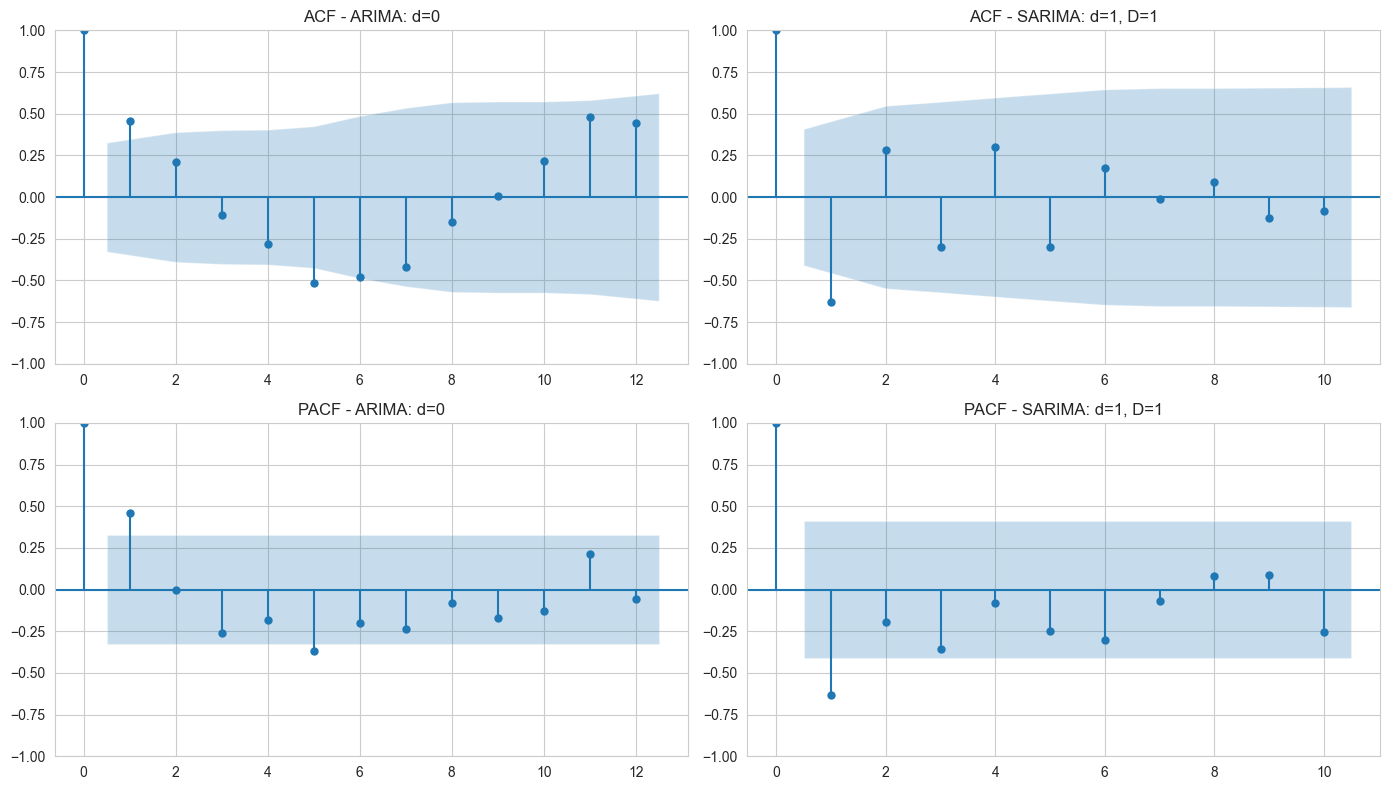

ARIMA: d=0: значимые лаги ACF [1, 5, 6, 7, 11, 12]; PACF [1, 5]
SARIMA: d=1, D=1: значимые лаги ACF [1]; PACF [1]


In [79]:
def stationary_view(y, d, D):
    x = y.diff(PERIOD) if D else y
    return (x.diff(d) if d else x).dropna()

def significant_lags(x, nlags, pacf=False):
    from statsmodels.tsa.stattools import acf, pacf as pacf_fn
    vals = pacf_fn(x, nlags=nlags, method="ywm") if pacf else acf(x, nlags=nlags, fft=False)
    bound = 1.96 / np.sqrt(len(x))
    return [k for k in range(1, nlags + 1) if abs(vals[k]) > bound]

views = {f"ARIMA: d={d_a}": stationary_view(y_train, d_a, 0), f"SARIMA: d={d_s}, D={D_s}": stationary_view(y_train, d_s, D_s)}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
sig_lags = {}
for j, (name, xx) in enumerate(views.items()):
    nl = min(PERIOD, len(xx) // 2 - 1)
    plot_acf(xx, lags=nl, ax=axes[0, j]); axes[0, j].set_title(f"ACF - {name}")
    plot_pacf(xx, lags=nl, ax=axes[1, j], method="ywm"); axes[1, j].set_title(f"PACF - {name}")
    sig_lags[name] = (significant_lags(xx, nl), significant_lags(xx, nl, pacf=True))
plt.tight_layout(); plt.show()

for name, (a_l, p_l) in sig_lags.items():
    print(f"{name}: значимые лаги ACF {a_l or 'нет'}; PACF {p_l or 'нет'}")

При небольшом числе наблюдений ACF/PACF могут быть неточными. Поэтому используем небольшие порядки моделей: `p, q ≤ 2`, `P, Q ≤ 1` (для ARIMA `p, q ≤ 3`). Лучшую модель выбираем по AIC внутри каждого семейства. Слишком сложные модели могут привести к переобучению.

## 2.2.4 Подбор моделей: ARIMA, SARIMA, SARIMAX

- **ARIMA** - учитывает только динамику ряда, без сезонности.
- **SARIMA** - учитывает сезонность с периодом `s = 12`.
- **SARIMAX** - учитывает сезонность и переменные `Promotion`, `HolidayMonth`.
- **SARIMAX-D0** - дополнительный вариант без сезонного дифференцирования `D = 0`.

В качестве базового варианта используется **seasonal naive** - значение того же месяца прошлого года.

Если признак после сезонного дифференцирования становится нулевым, он исключается из модели с `D = 1`.

Также проверяются варианты с константой/дрейфом. Модели, которые не сошлись, исключаются из сравнения.

In [80]:
def absorbed_by_seasonal_diff(col, D):
    # признак полностью обнуляется сезонным дифференцированием → в модели с D=1 он не идентифицируем
    return D == 1 and bool(np.allclose(ex_train[col].diff(PERIOD).dropna().values, 0))

cols_all = list(ex_train.columns)
cols_sx = [c for c in cols_all if not absorbed_by_seasonal_diff(c, D_s)]
dropped = [c for c in cols_all if c not in cols_sx]

if dropped:
    print(f"Признаки {dropped} исключены из SARIMAX с D={D_s}: после дифференцирования они становятся равны 0.")
    print("Их влияние проверяется в SARIMAX-D0.")
else:
    print("Все дополнительные признаки можно использовать в SARIMAX.")


def trend_options(total_diff, kind):
    if total_diff == 0:
        return ["n", "c"]
    if total_diff == 1:
        return ["n", "t"] if kind == "ARIMA" else ["n", "c"]
    return ["n"]


def fit_candidate(kind, y, exog_, order, seas, trend):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        if kind == "ARIMA":
            m = ARIMA(y, order=order, trend=trend).fit()
        else:
            m = SARIMAX(
                y,
                exog=exog_,
                order=order,
                seasonal_order=seas,
                trend=trend
            ).fit(disp=False, maxiter=300)

    conv = bool(getattr(m, "mle_retvals", {}).get("converged", True))
    return m, conv, len(w)


def grid_search(label, kind, y, cols, d, D):
    exog_ = ex_train[cols] if cols else None

    if kind == "ARIMA":
        space = [
            ((p, d, q), (0, 0, 0, 0), tr)
            for p in range(4)
            for q in range(4)
            for tr in trend_options(d + D, "ARIMA")
        ]
    else:
        space = [
            ((p, d, q), (P, D, Q, PERIOD), tr)
            for p in range(3)
            for q in range(3)
            for P in range(2)
            for Q in range(2)
            for tr in trend_options(d + D, kind)
        ]

    rows, models, failures = [], {}, []

    for order, seas, tr in space:
        key = (order, seas, tr)

        try:
            m, conv, nw = fit_candidate(kind, y, exog_, order, seas, tr)

            if not np.isfinite(m.aic):
                raise ValueError("AIC не конечен")

            models[key] = m
            rows.append({
                "order": order,
                "seasonal": seas if kind != "ARIMA" else "-",
                "trend": tr,
                "k": len(m.params),
                "AIC": m.aic,
                "BIC": m.bic,
                "converged": conv
            })

        except Exception as e:
            failures.append(
                f"{label}{order}x{seas} trend={tr}: "
                f"{type(e).__name__}: {str(e)[:80]}"
            )

    res = pd.DataFrame(rows)
    ok = res[res["converged"]].sort_values("AIC")

    print(
        f"{label}: проверено моделей - {len(space)}, "
        f"обучено - {len(res)}, "
        f"не сошлись - {int((~res['converged']).sum())}, "
        f"ошибок - {len(failures)}"
    )

    if failures:
        print("Примеры ошибок:", failures[:3])

    if ok.empty:
        print("Внимание: ни одна модель не сошлась. Выбирается модель с минимальным AIC.")
        ok = res.sort_values("AIC")

    best = ok.iloc[0]

    best_key = (
        best["order"],
        (0, 0, 0, 0) if kind == "ARIMA" else best["seasonal"],
        best["trend"]
    )

    return models[best_key], best_key, ok.reset_index(drop=True)


REG = {}   # реестр моделей: имя -> спецификация, обученная модель, таблица кандидатов

def register(name, kind, d, D, cols):
    m, key, tab = grid_search(name, kind, y_train, cols, d, D)

    REG[name] = dict(
        kind=kind,
        d=d,
        D=D,
        cols=cols,
        model=m,
        key=key,
        table=tab,
        burn=d + D * PERIOD
    )


register("ARIMA", "ARIMA", d_a, 0, [])
register("SARIMA", "SARIMAX", d_s, D_s, [])

if cols_sx:
    register("SARIMAX", "SARIMAX", d_s, D_s, cols_sx)

if D_s == 1:
    register("SARIMAX-D0", "SARIMAX", d_a, 0, cols_all)


for name, r in REG.items():
    print(f"\n{name}: лучшие модели по AIC")
    display(r["table"].head(5).round(2))

Признаки ['HolidayMonth'] исключены из SARIMAX с D=1: после дифференцирования они становятся равны 0.
Их влияние проверяется в SARIMAX-D0.
ARIMA: проверено моделей - 32, обучено - 32, не сошлись - 7, ошибок - 0
SARIMA: проверено моделей - 36, обучено - 36, не сошлись - 0, ошибок - 0
SARIMAX: проверено моделей - 36, обучено - 36, не сошлись - 0, ошибок - 0
SARIMAX-D0: проверено моделей - 72, обучено - 71, не сошлись - 1, ошибок - 1
Примеры ошибок: ['SARIMAX-D0(2, 0, 2)x(0, 0, 0, 12) trend=n: LinAlgError: LU decomposition error.']

ARIMA: лучшие модели по AIC


,order,seasonal,trend,k,AIC,BIC,converged
0,"(2, 0, 3)",-,c,7,644.06,655.14,True
1,"(3, 0, 3)",-,c,8,645.48,658.15,True
2,"(3, 0, 2)",-,c,7,650.04,661.13,True
3,"(1, 0, 0)",-,c,3,653.07,657.82,True
4,"(1, 0, 3)",-,c,6,653.75,663.25,True



SARIMA: лучшие модели по AIC


,order,seasonal,trend,k,AIC,BIC,converged
0,"(0, 1, 0)","(0, 1, 1, 12)",n,2,412.73,415.00,True
1,"(0, 1, 1)","(0, 1, 1, 12)",n,3,413.50,416.91,True
2,"(1, 1, 0)","(0, 1, 1, 12)",n,3,413.53,416.93,True
3,"(0, 1, 0)","(1, 1, 0, 12)",n,2,414.63,416.91,True
4,"(0, 1, 0)","(1, 1, 1, 12)",n,3,414.73,418.13,True



SARIMAX: лучшие модели по AIC


,order,seasonal,trend,k,AIC,BIC,converged
0,"(2, 1, 2)","(1, 1, 0, 12)",n,7,380.44,388.39,True
1,"(2, 1, 2)","(0, 1, 1, 12)",n,7,381.45,389.39,True
2,"(2, 1, 2)","(1, 1, 1, 12)",n,8,382.28,391.37,True
3,"(0, 1, 0)","(0, 1, 1, 12)",n,3,387.62,391.02,True
4,"(0, 1, 0)","(1, 1, 0, 12)",n,3,388.01,391.42,True



SARIMAX-D0: лучшие модели по AIC


,order,seasonal,trend,k,AIC,BIC,converged
0,"(0, 0, 2)","(0, 0, 1, 12)",c,7,618.09,629.18,True
1,"(1, 0, 2)","(0, 0, 0, 12)",n,6,633.47,642.97,True
2,"(1, 0, 0)","(0, 0, 1, 12)",n,5,634.41,642.32,True
3,"(1, 0, 0)","(0, 0, 1, 12)",c,6,634.60,644.10,True
4,"(0, 0, 0)","(0, 0, 1, 12)",c,5,638.36,646.28,True


## 2.2.5 Прогноз на тестовой выборке (12 месяцев) с доверительными интервалами

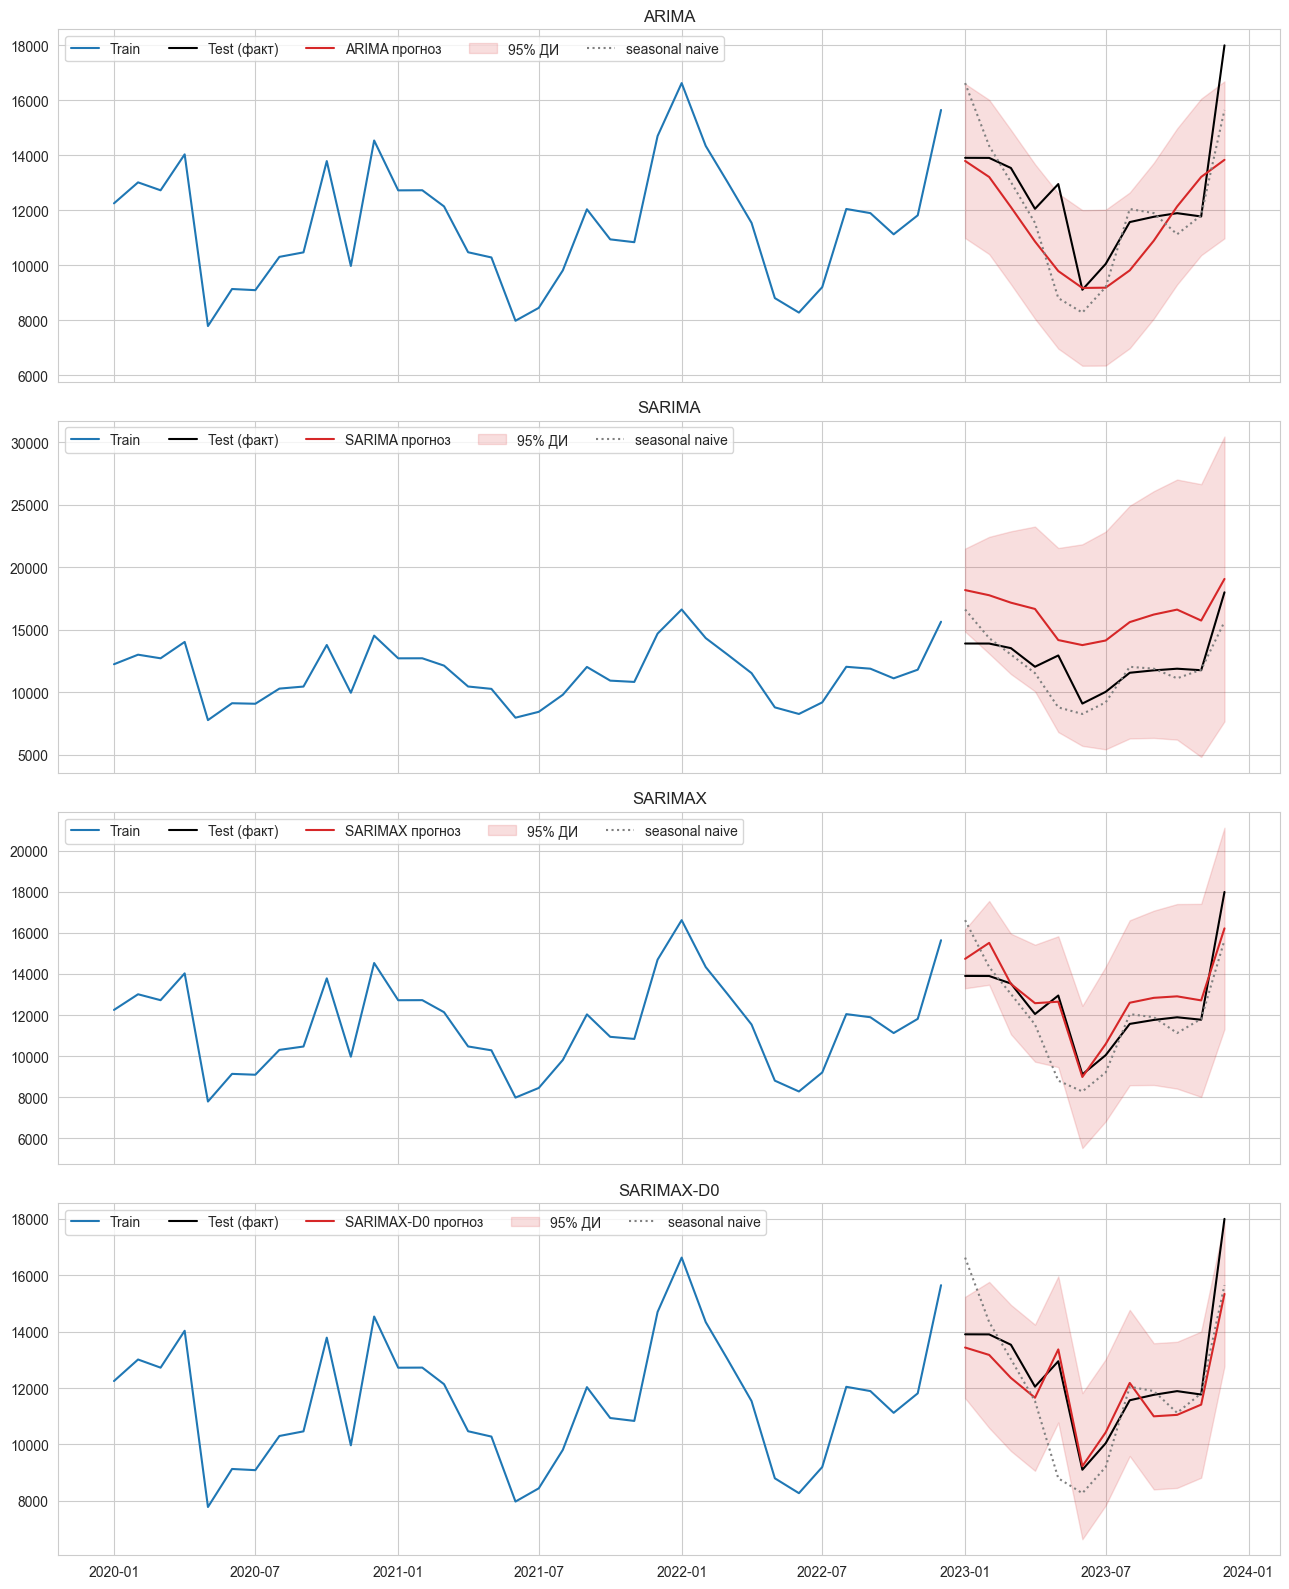

In [81]:
def get_fc(r, steps):
    ex = ex_test[r["cols"]] if r["cols"] else None
    fc = r["model"].get_forecast(steps=steps, exog=ex)
    ci = fc.conf_int(alpha=0.05); ci.columns = ["lo", "hi"]
    return fc.predicted_mean, ci

FC = {name: get_fc(r, N_TEST) for name, r in REG.items()}
fc_snaive = pd.Series(y_train.iloc[-PERIOD:].values, index=y_test.index)       # seasonal naive

fig, axes = plt.subplots(len(FC), 1, figsize=(13, 4 * len(FC)), sharex=True)
for ax, (nm, (fc, ci)) in zip(np.atleast_1d(axes), FC.items()):
    ax.plot(y_train, label="Train"); ax.plot(y_test, label="Test (факт)", c="k"); ax.plot(fc, label=f"{nm} прогноз", c="C3")
    ax.fill_between(ci.index, ci["lo"], ci["hi"], color="C3", alpha=.15, label="95% ДИ")
    ax.plot(fc_snaive, ls=":", c="gray", label="seasonal naive"); ax.set_title(nm); ax.legend(ncol=5, loc="upper left")
plt.tight_layout(); plt.show()

## 2.2.6 Максимальный горизонт прогноза с приемлемым качеством

Чтобы определить максимальный горизонт прогноза, проверяем качество модели для горизонтов от 1 до 12 месяцев.

Используется rolling-origin: модель каждый раз обучается на доступных данных и строит прогноз на несколько месяцев вперёд.

Качество считаем приемлемым, если `R² ≥ 0.5` и `MAPE ≤ 10%`.

Максимальный горизонт - последний горизонт, для которого условие выполняется на всех предыдущих горизонтах.

Строк в rolling-таблице: 1110 | пропусков прогноза: 0


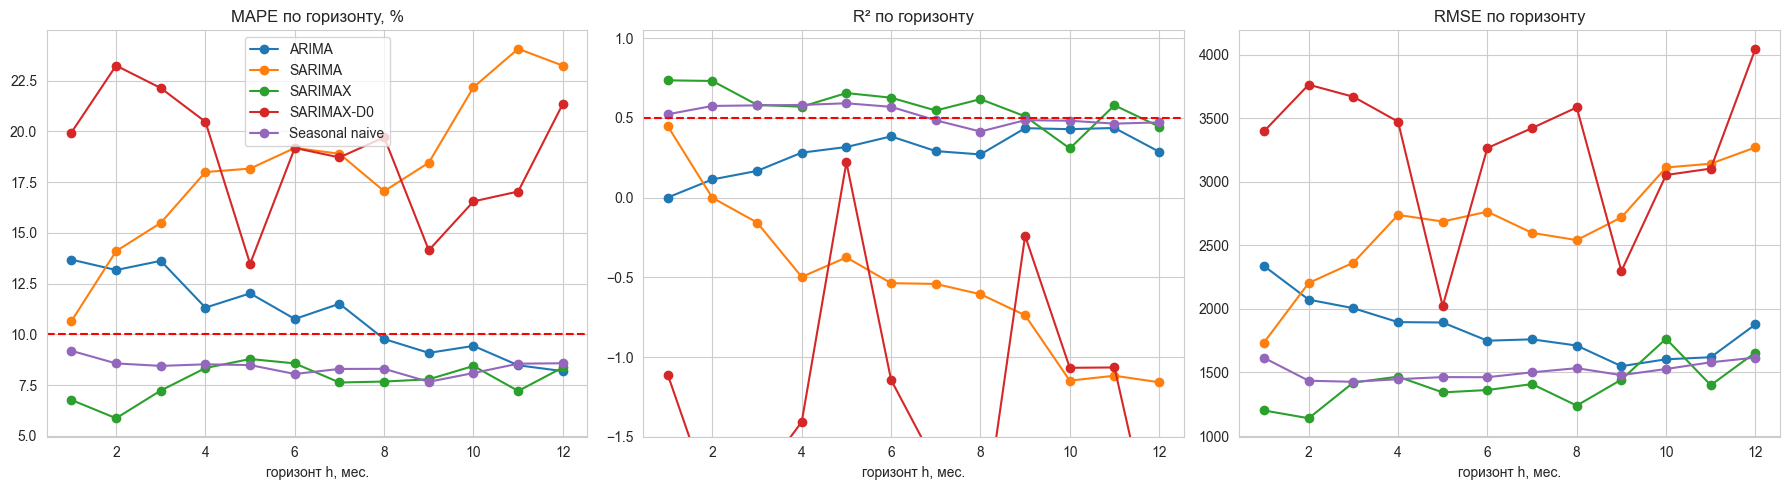

model,ARIMA,SARIMA,SARIMAX,SARIMAX-D0,Seasonal naive
"MAPE, % по горизонту h",,,,,
1,13.7,10.6,6.8,19.9,9.2
2,13.2,14.1,5.9,23.2,8.6
3,13.6,15.5,7.2,22.1,8.4
4,11.3,18.0,8.3,20.5,8.5
5,12.0,18.2,8.8,13.5,8.5
6,10.8,19.2,8.6,19.2,8.0
7,11.5,18.9,7.6,18.7,8.3
8,9.8,17.0,7.7,19.7,8.3
9,9.1,18.5,7.8,14.1,7.7


model,ARIMA,SARIMA,SARIMAX,SARIMAX-D0,Seasonal naive
R² по горизонту h,,,,,
1,0.00,0.45,0.74,-1.11,0.52
2,0.11,-0.00,0.73,-1.92,0.58
3,0.17,-0.16,0.58,-1.78,0.58
4,0.28,-0.50,0.57,-1.41,0.58
5,0.32,-0.37,0.66,0.22,0.59
6,0.38,-0.54,0.63,-1.14,0.57
7,0.29,-0.54,0.55,-1.67,0.49
8,0.27,-0.61,0.62,-2.20,0.42
9,0.44,-0.74,0.51,-0.24,0.49


Максимальный горизонт, на котором критерий (R² ≥ 0.5 и MAPE ≤ 10%) выполнен на всех шагах 1…H:
   ARIMA          : H = 0  (критерий не выполнен уже при h=1)
   SARIMA         : H = 0  (критерий не выполнен уже при h=1)
   SARIMAX        : H = 9
   SARIMAX-D0     : H = 0  (критерий не выполнен уже при h=1)
   Seasonal naive : H = 6


In [82]:
def rolling_origin(min_train=MIN_TRAIN_ROLL, H=H_MAX):
    rows = []
    for origin in range(min_train, len(y_full)):
        hm = min(H, len(y_full) - origin)
        yt = y_full.iloc[:origin]
        for name, r in REG.items():
            order, seas, tr = r["key"]; cols = r["cols"]
            try:
                m, _, _ = fit_candidate(r["kind"], yt, exog[cols].iloc[:origin] if cols else None, order, seas, tr)
                pred = m.forecast(steps=hm, exog=exog[cols].iloc[origin:origin + hm] if cols else None).values
            except Exception:
                pred = np.full(hm, np.nan)
            for h in range(1, hm + 1):
                rows.append({"model": name, "origin": origin, "h": h, "actual": y_full.iloc[origin + h - 1], "pred": pred[h - 1]})
        for h in range(1, hm + 1):    # seasonal naive: значение год назад
            rows.append({"model": "Seasonal naive", "origin": origin, "h": h, "actual": y_full.iloc[origin + h - 1],
                         "pred": y_full.iloc[origin + h - 1 - PERIOD]})
    return pd.DataFrame(rows)

roll = rolling_origin()
print("Строк в rolling-таблице:", len(roll), "| пропусков прогноза:", int(roll["pred"].isna().sum()))

def metrics_by_h(g):
    g = g.dropna(subset=["pred"])
    if len(g) < 3: return pd.Series({"n": len(g), "MSE": np.nan, "RMSE": np.nan, "MAPE, %": np.nan, "R2": np.nan})
    mse = mean_squared_error(g["actual"], g["pred"])
    return pd.Series({"n": len(g), "MSE": mse, "RMSE": np.sqrt(mse),
                      "MAPE, %": 100 * np.mean(np.abs((g["actual"] - g["pred"]) / g["actual"])),
                      "R2": r2_score(g["actual"], g["pred"])})

by_h = pd.DataFrame([{"model": m_, "h": h_, **metrics_by_h(g).to_dict()} for (m_, h_), g in roll.groupby(["model", "h"])])

def max_ok_horizon(tab):
    ok = 0
    for h in range(1, H_MAX + 1):
        row = tab[tab["h"] == h]
        if row.empty or row["R2"].isna().iloc[0]: break
        if row["R2"].iloc[0] >= ACCEPT_R2 and row["MAPE, %"].iloc[0] <= ACCEPT_MAPE: ok = h
        else: break
    return ok

horizon_ok = {m_: max_ok_horizon(by_h[by_h["model"] == m_]) for m_ in by_h["model"].unique()}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for m_, g in by_h.groupby("model"):
    axes[0].plot(g["h"], g["MAPE, %"], marker="o", label=m_); axes[1].plot(g["h"], g["R2"], marker="o", label=m_); axes[2].plot(g["h"], g["RMSE"], marker="o", label=m_)
axes[0].axhline(ACCEPT_MAPE, ls="--", c="r"); axes[0].set_title("MAPE по горизонту, %"); axes[0].set_xlabel("горизонт h, мес.")
axes[1].axhline(ACCEPT_R2, ls="--", c="r"); axes[1].set_title("R² по горизонту"); axes[1].set_xlabel("горизонт h, мес."); axes[1].set_ylim(-1.5, 1.05)
axes[2].set_title("RMSE по горизонту"); axes[2].set_xlabel("горизонт h, мес."); axes[0].legend()
plt.tight_layout(); plt.show()

display(by_h.pivot(index="h", columns="model", values="MAPE, %").round(1).rename_axis("MAPE, % по горизонту h"))
display(by_h.pivot(index="h", columns="model", values="R2").round(2).rename_axis("R² по горизонту h"))
print("Максимальный горизонт, на котором критерий (R² ≥ %.1f и MAPE ≤ %.0f%%) выполнен на всех шагах 1…H:" % (ACCEPT_R2, ACCEPT_MAPE))
for k_, v_ in horizon_ok.items(): print(f"   {k_:15s}: H = {v_}" + ("  (критерий не выполнен уже при h=1)" if v_ == 0 else ""))

### Вывод по пункту 2.2

In [83]:
model_only = {k: v for k, v in horizon_ok.items() if k != "Seasonal naive"}
best_h_model = max(model_only, key=model_only.get)
print(f"• Порядки дифференцирования выбраны по train формально: ARIMA d={d_a}; SARIMA/SARIMAX d={d_s}, D={D_s} (F_s={Fs_tr:.2f}).")
if d_a == 0:
    print("  Для ARIMA тесты признали ряд стационарным (d=0) - поэтому она описывает только среднее/слабую динамику и не умеет воспроизводить сезонность.")
for name, r in REG.items():
    print(f"• {name}: порядок {r['key'][0]}, сезонная часть {r['key'][1]}, trend={r['key'][2]}, exog={r['cols'] or '-'}.")
if dropped:
    print(f"• Признаки {dropped} невозможно использовать в моделях с D=1 (поглощены сезонным дифференцированием); их эффект оценивается в SARIMAX-D0.")
for name, r in REG.items():
    for c in r["cols"]:
        pv = r["model"].pvalues.get(c, np.nan)
        print(f"• {name}: {c} p={pv:.3f} ({'значим' if pv < ALPHA else 'не значим'}).")
print("• Максимальный горизонт с приемлемым качеством (критерий задан заранее): " + "; ".join(f"{k}: {v} мес." for k, v in horizon_ok.items()))
if horizon_ok[best_h_model] == 0: print("  Ни одна модель не удовлетворила критерию даже на 1 шаг - критерий жёсткий для столь короткого ряда; см. таблицы по горизонту.")
elif horizon_ok[best_h_model] >= H_MAX: print(f"  Лучшая модель ({best_h_model}) удовлетворяет критерию на всём проверенном диапазоне 1…{H_MAX}; более длинный горизонт при 48 наблюдениях проверить невозможно.")
else: print(f"  Лучшая модель ({best_h_model}) теряет приемлемое качество после горизонта {horizon_ok[best_h_model]} мес.")

• Порядки дифференцирования выбраны по train формально: ARIMA d=0; SARIMA/SARIMAX d=1, D=1 (F_s=0.92).
  Для ARIMA тесты признали ряд стационарным (d=0) - поэтому она описывает только среднее/слабую динамику и не умеет воспроизводить сезонность.
• ARIMA: порядок (2, 0, 3), сезонная часть (0, 0, 0, 0), trend=c, exog=-.
• SARIMA: порядок (0, 1, 0), сезонная часть (0, 1, 1, 12), trend=n, exog=-.
• SARIMAX: порядок (2, 1, 2), сезонная часть (1, 1, 0, 12), trend=n, exog=['Promotion'].
• SARIMAX-D0: порядок (0, 0, 2), сезонная часть (0, 0, 1, 12), trend=c, exog=['Promotion', 'HolidayMonth'].
• Признаки ['HolidayMonth'] невозможно использовать в моделях с D=1 (поглощены сезонным дифференцированием); их эффект оценивается в SARIMAX-D0.
• SARIMAX: Promotion p=0.000 (значим).
• SARIMAX-D0: Promotion p=0.000 (значим).
• SARIMAX-D0: HolidayMonth p=0.000 (значим).
• Максимальный горизонт с приемлемым качеством (критерий задан заранее): ARIMA: 0 мес.; SARIMA: 0 мес.; SARIMAX: 9 мес.; SARIMAX-D0: 0 м

# 2.3 Оценка качества моделей

## 2.3.1 Метрики на тесте и информационные критерии

- **MSE, RMSE, MAE, MAPE, R²** - рассчитываются на тестовых 12 месяцах.
- **AIC и BIC** - используются для сравнения моделей с одинаковыми `d`, `D` и данными.
- Для сравнения разных моделей дополнительно используется оценка AIC/BIC на общей выборке.

Общая выборка для AIC*/BIC*: остатки после первых 13 наблюдений


,MSE,RMSE,MAE,"MAPE, %",R2,k,AIC,BIC,AIC*,BIC*,n(IC*)
Модель,,,,,,,,,,,
ARIMA,3.168847e+06,1780.125,1332.237,9.996,0.315,7.0,644.059,655.144,411.134,419.082,23.0
SARIMA,1.528080e+07,3909.066,3721.769,31.475,-2.304,2.0,412.730,415.001,413.283,415.554,23.0
SARIMAX,9.398732e+05,969.471,817.245,6.311,0.797,7.0,380.437,388.385,380.131,388.080,23.0
SARIMAX-D0,9.574937e+05,978.516,744.003,5.473,0.793,7.0,618.093,629.178,396.284,404.233,23.0
Seasonal naive,2.757115e+06,1660.456,1147.583,8.784,0.404,NaN,NaN,NaN,NaN,NaN,NaN


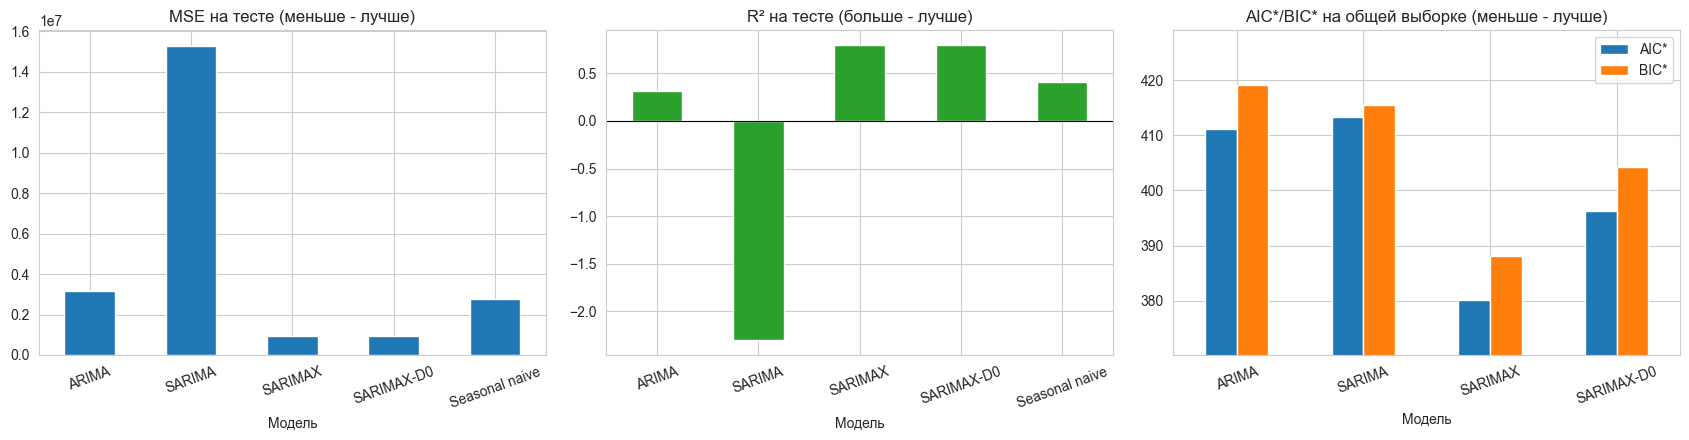

Штатные AIC/BIC корректно сравнимы внутри группы с одинаковыми (d, D)=(1, 1): ['SARIMA', 'SARIMAX']; остальные - только по AIC*/BIC*.


In [84]:
def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_true, y_pred),
            "MAPE, %": 100 * np.mean(np.abs((y_true - y_pred) / y_true)), "R2": r2_score(y_true, y_pred)}

BURN_COMMON = max(r["burn"] for r in REG.values())
print(f"Общая выборка для AIC*/BIC*: остатки после первых {BURN_COMMON} наблюдений")

def common_ic(model, burn):
    e = np.asarray(model.resid)[burn:]; n = len(e); k = len(model.params)
    ll = -0.5 * n * (np.log(2 * np.pi * np.mean(e ** 2)) + 1)
    return 2 * k - 2 * ll, k * np.log(n) - 2 * ll, n

forecasts = {nm: fc for nm, (fc, ci) in FC.items()}; forecasts["Seasonal naive"] = fc_snaive
fitted = {nm: r["model"] for nm, r in REG.items()}
rows = []
for name, fc in forecasts.items():
    row = {"Модель": name, **reg_metrics(y_test.values, fc.values)}
    if name in fitted:
        m = fitted[name]; a_c, b_c, n_c = common_ic(m, BURN_COMMON)
        row.update({"k": len(m.params), "AIC": m.aic, "BIC": m.bic, "AIC*": a_c, "BIC*": b_c, "n(IC*)": n_c})
    rows.append(row)
comparison = pd.DataFrame(rows).set_index("Модель")
display(comparison.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
comparison["MSE"].plot.bar(ax=axes[0], color="C0", rot=20); axes[0].set_title("MSE на тесте (меньше - лучше)")
comparison["R2"].plot.bar(ax=axes[1], color="C2", rot=20); axes[1].axhline(0, c="k", lw=.8); axes[1].set_title("R² на тесте (больше - лучше)")
comparison.dropna(subset=["AIC*"])[["AIC*", "BIC*"]].plot.bar(ax=axes[2], rot=20); axes[2].set_title("AIC*/BIC* на общей выборке (меньше - лучше)")
axes[2].set_ylim(comparison["AIC*"].min() - 10, comparison["BIC*"].max() + 10)
plt.tight_layout(); plt.show()

same_dD = [nm for nm, r in REG.items() if (r["d"], r["D"]) == (d_s, D_s)]
print(f"Штатные AIC/BIC корректно сравнимы внутри группы с одинаковыми (d, D)=({d_s}, {D_s}): {same_dD}; остальные - только по AIC*/BIC*.")

## 2.3.2 Анализ остатков

Для каждой модели анализируем остатки после удаления первых `d + D·12` наблюдений.

Проверяем:
- **Нормальность** - Jarque-Bera, Shapiro-Wilk, QQ-plot.
- **Автокорреляцию** - Ljung-Box и Durbin-Watson.
- **Гомоскедастичность** - Breusch-Pagan, Goldfeld-Quandt и ARCH-LM.

,n остатков,Среднее остатков,JB p,Shapiro p,DW,BP p,GQ p,ARCH p,LB p(6),LB p(12)
Модель,,,,,,,,,,
ARIMA,36,-32.2962,0.3476,0.6693,1.9253,0.4647,0.6482,0.5283,0.1274,0.3614
SARIMA,23,-121.6445,0.7527,0.7213,2.6577,0.1535,0.0684,0.0882,0.0357,0.1481
SARIMAX,23,-60.5315,0.7448,0.7814,2.4055,0.3877,0.4124,0.7602,0.0032,0.0287
SARIMAX-D0,36,-1.9267,0.3484,0.2778,1.7113,0.2098,0.7267,0.5741,0.1233,0.1362


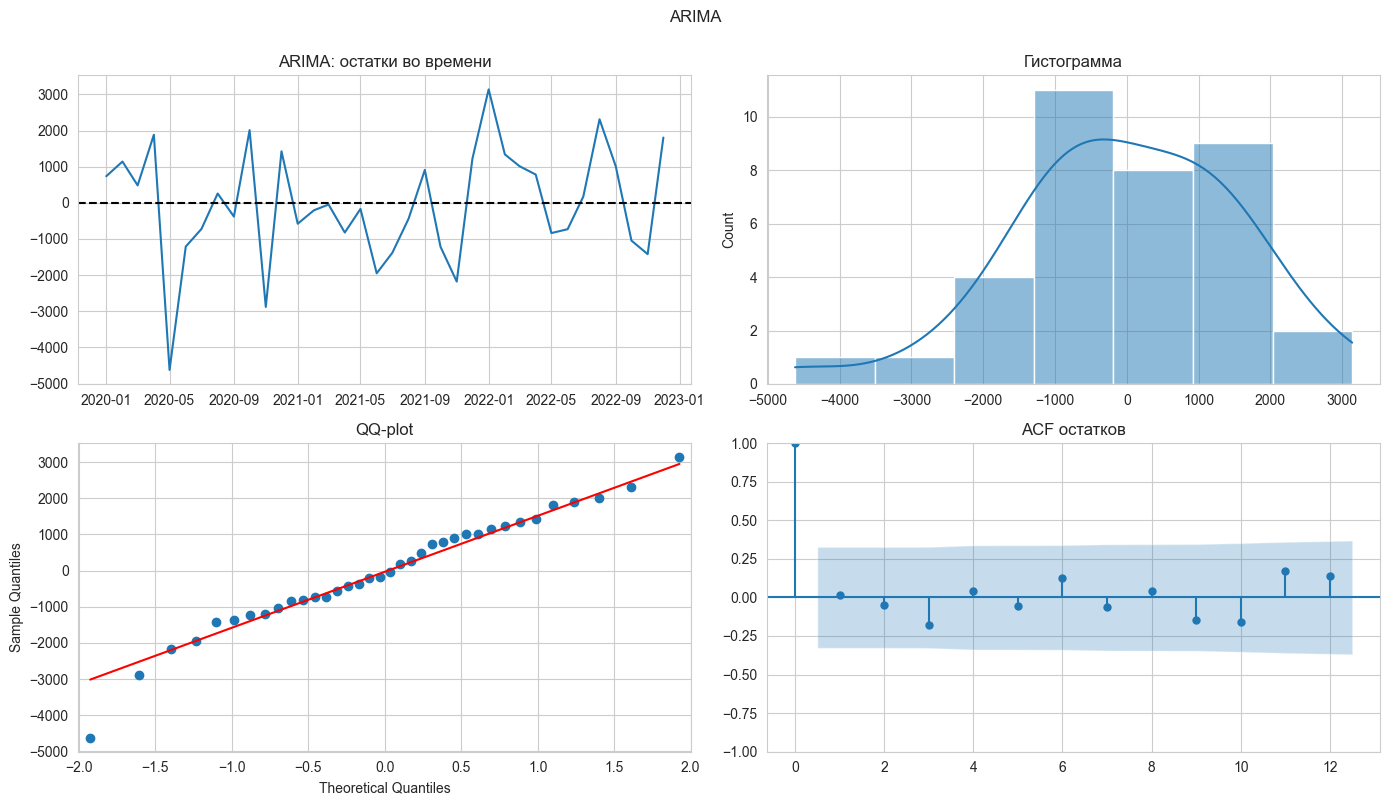

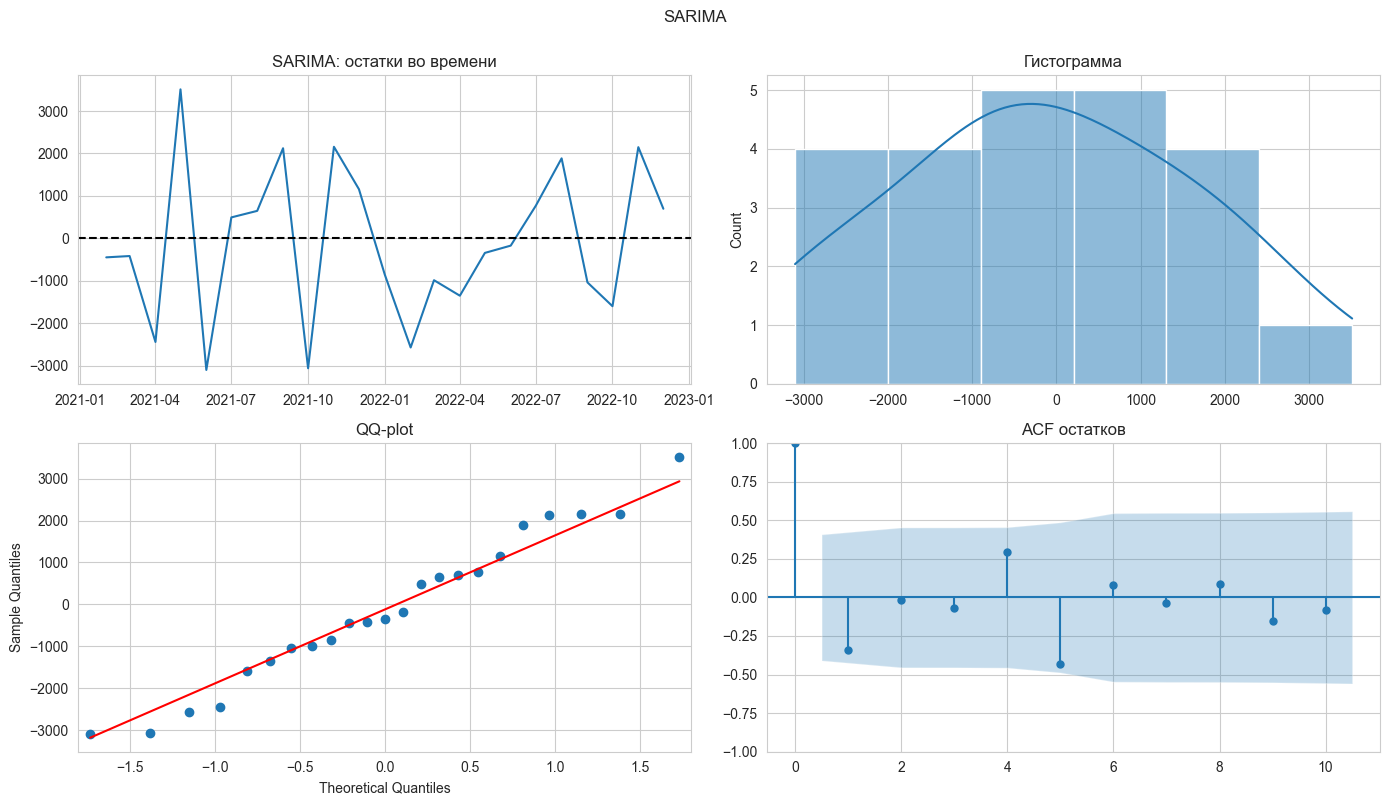

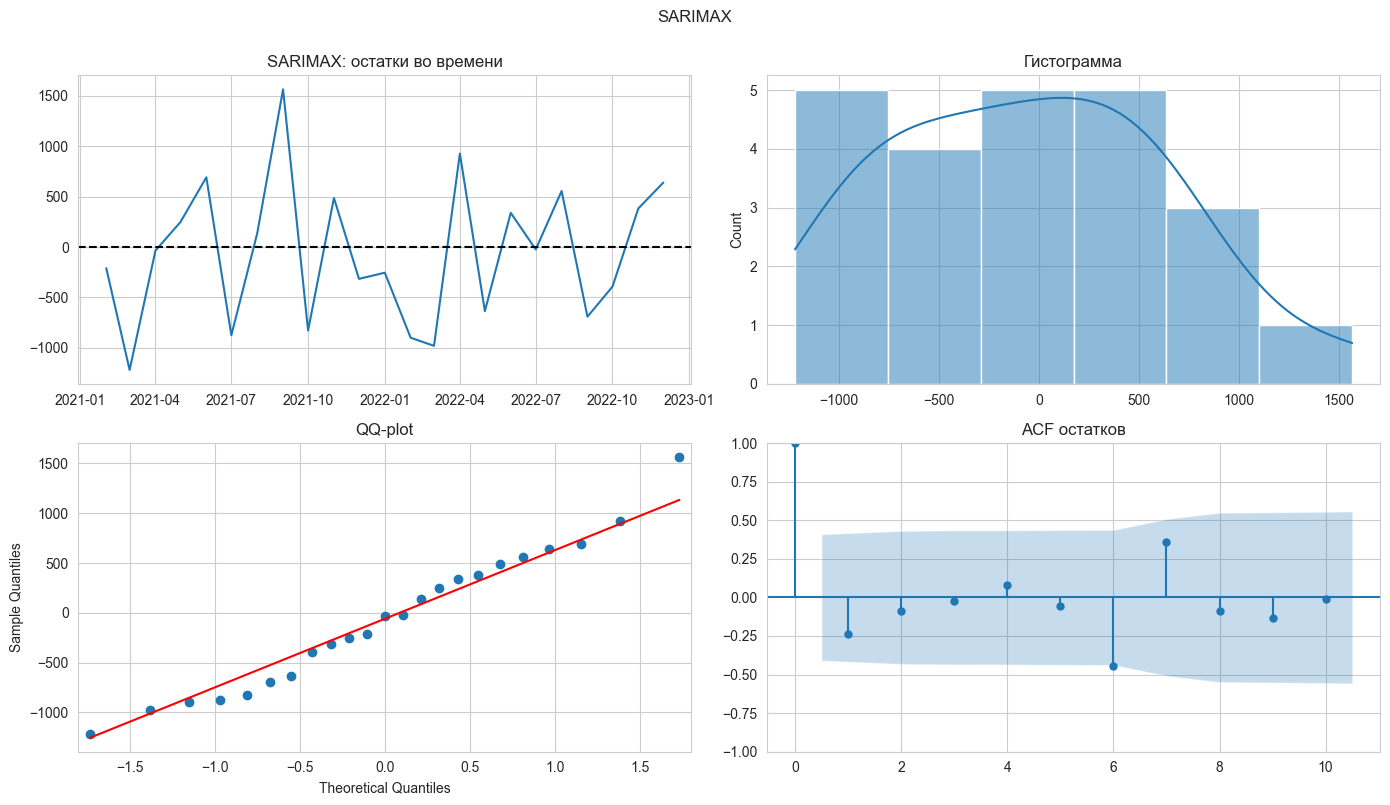

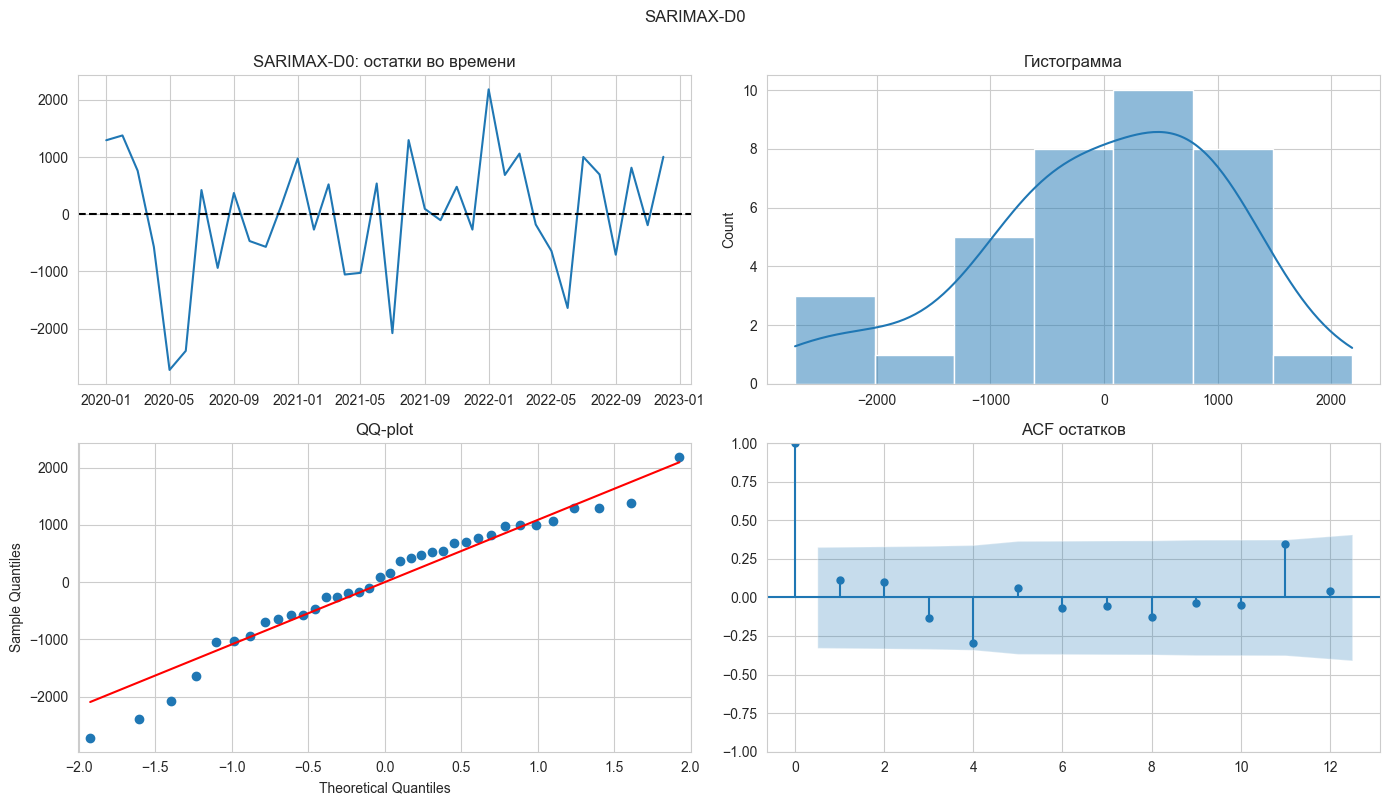

In [85]:
own_burn = {nm: r["burn"] for nm, r in REG.items()}
arma_df = {nm: int(sum(k.startswith(("ar.", "ma.")) for k in m.params.index)) for nm, m in fitted.items()}

def diagnose(name, model):
    e = pd.Series(np.asarray(model.resid), index=y_train.index).iloc[own_burn[name]:]
    n = len(e)
    jb_p = stats.jarque_bera(e).pvalue; sh_p = stats.shapiro(e).pvalue
    lags = [l for l in (6, 12) if arma_df[name] < l < n - 1]
    lb = acorr_ljungbox(e, lags=lags, model_df=arma_df[name], return_df=True)["lb_pvalue"] if lags else pd.Series(dtype=float)
    t = sm.add_constant(np.arange(n).astype(float))
    bp_p = het_breuschpagan(e.values, t)[1]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            gq_p = het_goldfeldquandt(e.values, t, alternative="two-sided")[1]
    except Exception: gq_p = np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # FutureWarning о формате возвращаемого кортежа
        arch_p = het_arch(e.values, nlags=max(1, min(4, n // 5)))[1]
    out = {"Модель": name, "n остатков": n, "Среднее остатков": e.mean(), "JB p": jb_p, "Shapiro p": sh_p, "DW": durbin_watson(e.values),
           "BP p": bp_p, "GQ p": gq_p, "ARCH p": arch_p}
    for l in (6, 12): out[f"LB p({l})"] = lb.get(l, np.nan)
    return out, e

diag_rows, resids = [], {}
for nm, m in fitted.items():
    row, e = diagnose(nm, m); diag_rows.append(row); resids[nm] = e
diag_df = pd.DataFrame(diag_rows).set_index("Модель"); display(diag_df.round(4))

for nm, e in resids.items():
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes[0, 0].plot(e); axes[0, 0].axhline(0, ls="--", c="k"); axes[0, 0].set_title(f"{nm}: остатки во времени")
    sns.histplot(e, kde=True, ax=axes[0, 1]); axes[0, 1].set_title("Гистограмма")
    qqplot(e, line="s", ax=axes[1, 0]); axes[1, 0].set_title("QQ-plot")
    plot_acf(e, lags=min(12, len(e) // 2 - 1), ax=axes[1, 1]); axes[1, 1].set_title("ACF остатков")
    plt.suptitle(nm, y=1.0); plt.tight_layout(); plt.show()

In [86]:
def interpret(name, r):
    msgs = []
    msgs.append("нормальность: " + ("не отвергается (JB и Shapiro)" if min(r["JB p"], r["Shapiro p"]) >= ALPHA
                                     else f"отвергается (JB p={r['JB p']:.3f}, Shapiro p={r['Shapiro p']:.3f})"))
    lbs = [r[c] for c in ("LB p(6)", "LB p(12)") if not np.isnan(r[c])]
    msgs.append("автокорреляция: " + ("не обнаружена (Ljung-Box)" if lbs and min(lbs) >= ALPHA else "обнаружена (Ljung-Box)" if lbs else "Ljung-Box не применим (слишком короткая выборка)")
                + f", DW={r['DW']:.2f}")
    hs = [r["BP p"], r["GQ p"], r["ARCH p"]]; hs = [h for h in hs if not np.isnan(h)]
    msgs.append("гомоскедастичность: " + ("не отвергается" if min(hs) >= ALPHA else f"отвергается хотя бы одним тестом (BP p={r['BP p']:.3f}, GQ p={r['GQ p']:.3f}, ARCH p={r['ARCH p']:.3f})"))
    return f"{name} (n={int(r['n остатков'])}): " + "; ".join(msgs)

for nm, r in diag_df.iterrows(): print("•", interpret(nm, r))
print("\nПримечание: при 20-35 остатках мощность тестов мала - «не отвергается» не равно «доказано».")

• ARIMA (n=36): нормальность: не отвергается (JB и Shapiro); автокорреляция: не обнаружена (Ljung-Box), DW=1.93; гомоскедастичность: не отвергается
• SARIMA (n=23): нормальность: не отвергается (JB и Shapiro); автокорреляция: обнаружена (Ljung-Box), DW=2.66; гомоскедастичность: не отвергается
• SARIMAX (n=23): нормальность: не отвергается (JB и Shapiro); автокорреляция: обнаружена (Ljung-Box), DW=2.41; гомоскедастичность: не отвергается
• SARIMAX-D0 (n=36): нормальность: не отвергается (JB и Shapiro); автокорреляция: не обнаружена (Ljung-Box), DW=1.71; гомоскедастичность: не отвергается

Примечание: при 20-35 остатках мощность тестов мала - «не отвергается» не равно «доказано».


## 2.3.3 Итоговое сравнение и выбор модели

In [87]:
cand = comparison.drop(index="Seasonal naive")
winner_test = cand["MSE"].idxmin()
winner_ic   = cand["AIC*"].idxmin()
winner_bic  = cand["BIC*"].idxmin()
roll_mse = by_h.groupby("model")["MSE"].mean()
winner_roll = roll_mse.drop("Seasonal naive", errors="ignore").idxmin()

summary_choice = pd.DataFrame({
    "MSE (тест)": cand["MSE"], "R² (тест)": cand["R2"], "MAPE % (тест)": cand["MAPE, %"],
    "Средний MSE rolling (h=1..12)": roll_mse.reindex(cand.index),
    "AIC*": cand["AIC*"], "BIC*": cand["BIC*"],
    "Макс. горизонт H": pd.Series(horizon_ok).reindex(cand.index)})
display(summary_choice.round(2))
print(f"Лучшая по MSE на тесте: {winner_test}; по rolling-MSE: {winner_roll}; по AIC*: {winner_ic}; по BIC*: {winner_bic}")
beats_naive = cand.loc[winner_test, "MSE"] < comparison.loc["Seasonal naive", "MSE"]
print(f"Лучшая модель {'обыгрывает' if beats_naive else 'НЕ обыгрывает'} seasonal naive (MSE {cand.loc[winner_test,'MSE']:.0f} против {comparison.loc['Seasonal naive','MSE']:.0f}).")

,MSE (тест),R² (тест),MAPE % (тест),Средний MSE rolling (h=1..12),AIC*,BIC*,Макс. горизонт H
Модель,,,,,,,
ARIMA,3168846.73,0.31,10.00,3430609.36,411.13,419.08,0
SARIMA,15280799.82,-2.30,31.47,7222240.33,413.28,415.55,0
SARIMAX,939873.17,0.80,6.31,1999199.25,380.13,388.08,9
SARIMAX-D0,957493.75,0.79,5.47,10926268.51,396.28,404.23,0


Лучшая по MSE на тесте: SARIMAX; по rolling-MSE: SARIMAX; по AIC*: SARIMAX; по BIC*: SARIMAX
Лучшая модель обыгрывает seasonal naive (MSE 939873 против 2757115).


### Вывод по пункту 2.3

In [88]:
print("• Прогнозное качество (тест, 12 мес.): " + "; ".join(f"{k}: R²={comparison.loc[k,'R2']:.2f}, MSE={comparison.loc[k,'MSE']:.0f}" for k in comparison.index) + ".")
if "SARIMA" in comparison.index and "ARIMA" in comparison.index:
    print(f"• Вклад сезонности: ARIMA → SARIMA меняет MSE в {comparison.loc['ARIMA','MSE']/comparison.loc['SARIMA','MSE']:.1f} раза.")
for nm in [n for n in ("SARIMAX", "SARIMAX-D0") if n in comparison.index]:
    base_nm = "SARIMA" if nm == "SARIMAX" else "ARIMA"
    ratio = comparison.loc[base_nm, "MSE"] / comparison.loc[nm, "MSE"]
    print(f"• Вклад экзогенных признаков ({base_nm} → {nm}): MSE меняется в {ratio:.2f} раза ({'улучшение' if ratio > 1 else 'улучшения нет'}).")
n_ic = int(comparison["n(IC*)"].dropna().iloc[0])
print(f"• Информационные критерии (общая выборка n={n_ic}): по AIC* лучшая - {winner_ic}, по BIC* - {winner_bic}. BIC сильнее штрафует сложность и предпочитает более простые модели.")
winners = {winner_test, winner_ic, winner_bic, winner_roll}
print(f"• Критерии согласованы: {'да' if len(winners) == 1 else 'нет - разные критерии указывают на разные модели: ' + str(winners)}.")
print("• Остатки: " + " | ".join(interpret(nm, r) for nm, r in diag_df.iterrows()))
print("• Следствие для выбора: решающим считаем качество на отложенных данных (test + rolling), информационные критерии - вспомогательный аргумент против переобучения.")

• Прогнозное качество (тест, 12 мес.): ARIMA: R²=0.31, MSE=3168847; SARIMA: R²=-2.30, MSE=15280800; SARIMAX: R²=0.80, MSE=939873; SARIMAX-D0: R²=0.79, MSE=957494; Seasonal naive: R²=0.40, MSE=2757115.
• Вклад сезонности: ARIMA → SARIMA меняет MSE в 0.2 раза.
• Вклад экзогенных признаков (SARIMA → SARIMAX): MSE меняется в 16.26 раза (улучшение).
• Вклад экзогенных признаков (ARIMA → SARIMAX-D0): MSE меняется в 3.31 раза (улучшение).
• Информационные критерии (общая выборка n=23): по AIC* лучшая - SARIMAX, по BIC* - SARIMAX. BIC сильнее штрафует сложность и предпочитает более простые модели.
• Критерии согласованы: да.
• Остатки: ARIMA (n=36): нормальность: не отвергается (JB и Shapiro); автокорреляция: не обнаружена (Ljung-Box), DW=1.93; гомоскедастичность: не отвергается | SARIMA (n=23): нормальность: не отвергается (JB и Shapiro); автокорреляция: обнаружена (Ljung-Box), DW=2.66; гомоскедастичность: не отвергается | SARIMAX (n=23): нормальность: не отвергается (JB и Shapiro); автокорре

# 2.4 Итоговые выводы

In [91]:
best = winner_test if winner_test == winner_roll else winner_roll
print("1. EDA и декомпозиция")
print(f"   Ряд из {len(y_full)} месячных точек; сила тренда F_t={Ft_full:.2f}, сила сезонности F_s={Fs_full:.2f}. "
      f"Годовой период подтверждён {n_yes} из {len(agree)} независимых методов (STL, FFT, CWT). Рекомендованная форма: {best_classic}.")
print(f"   HolidayMonth даёт {hol_coef:+.0f} ед. (p={hol_p:.3f}); Promotion {pro_coef:+.0f} ед. (p={pro_p:.3f}).")
print("2. Подбор моделей")
print(f"   d, D выбраны по train формально (ARIMA d={d_a}; SARIMA/SARIMAX d={d_s}, D={D_s}); порядки ARMA - по AIC в семействе с одинаковым дифференцированием.")
if dropped: print(f"   Признаки {dropped} поглощаются сезонным дифференцированием → дополнительно построена SARIMAX-D0.")
print("3. Качество (тест, 12 мес.)")
for k in comparison.index: print(f"   {k:15s} R²={comparison.loc[k,'R2']:6.2f}   MSE={comparison.loc[k,'MSE']:12.0f}   MAPE={comparison.loc[k,'MAPE, %']:5.1f}%")
print(f"   Максимальный горизонт с приемлемым качеством (R²≥{ACCEPT_R2}, MAPE≤{ACCEPT_MAPE:.0f}%): " + "; ".join(f"{k}={v} мес." for k, v in horizon_ok.items()))
print("4. Остатки")
for nm, r in diag_df.iterrows(): print("   " + interpret(nm, r))
print("5. Предпочтительная модель")
print(f"  - {best}. Критерии: тест - {winner_test}, rolling - {winner_roll}, AIC* - {winner_ic}, BIC* - {winner_bic}.")
if REG[best]["cols"]:
    print(f"   Прогноз {best} условный: он требует заранее известных {REG[best]['cols']} на горизонте прогноза.")

1. EDA и декомпозиция
   Ряд из 48 месячных точек; сила тренда F_t=0.26, сила сезонности F_s=0.84. Годовой период подтверждён 3 из 3 независимых методов (STL, FFT, CWT). Рекомендованная форма: additive.
   HolidayMonth даёт +4378 ед. (p=0.000); Promotion +1851 ед. (p=0.133).
2. Подбор моделей
   d, D выбраны по train формально (ARIMA d=0; SARIMA/SARIMAX d=1, D=1); порядки ARMA - по AIC в семействе с одинаковым дифференцированием.
   Признаки ['HolidayMonth'] поглощаются сезонным дифференцированием → дополнительно построена SARIMAX-D0.
3. Качество (тест, 12 мес.)
   ARIMA           R²=  0.31   MSE=     3168847   MAPE= 10.0%
   SARIMA          R²= -2.30   MSE=    15280800   MAPE= 31.5%
   SARIMAX         R²=  0.80   MSE=      939873   MAPE=  6.3%
   SARIMAX-D0      R²=  0.79   MSE=      957494   MAPE=  5.5%
   Seasonal naive  R²=  0.40   MSE=     2757115   MAPE=  8.8%
   Максимальный горизонт с приемлемым качеством (R²≥0.5, MAPE≤10%): ARIMA=0 мес.; SARIMA=0 мес.; SARIMAX=9 мес.; SARIMAX-